# Computes ground relative cold pool speed 
Computes the ground relative cold pool speed along a transect, following the edge of the cold pool by taking the gradient of the theta perturbation. For the south MCS.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
from netCDF4 import Dataset, num2date, date2num
from datetime import datetime
from matplotlib.dates import DateFormatter
import pandas as pd 

import metpy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import matplotlib.ticker as mticker 
from __future__ import print_function
import os
import glob

from metpy.units import units
from matplotlib.ticker import ScalarFormatter
from metpy.interpolate import cross_section

import wrf
import metpy.calc as mpcalc
from metpy.calc import relative_humidity_from_mixing_ratio
from wrf import (to_np, interplevel, geo_bounds, getvar, smooth2d, get_cartopy, cartopy_xlim,
                 cartopy_ylim, latlon_coords, destagger, CoordPair, vertcross, ll_to_xy)

In [2]:
# Set directory where wrfout files reside, and list the files for processing.  Set up for a directory with only wrfout files.
os.chdir("/glade/campaign/univ/uncs0067/cold_pool_experiments/coldpool1/")
print(os.getcwd())
# Get sorted list of files
datafiles = (sorted(glob.glob("wrfout_d03*")))#17_00:00:00")))
numfiles=len(datafiles)
print(numfiles)
print(datafiles[44])
# Set up for saving graphics files
plotsdir = '/glade/u/home/athornton/wrf_visualization/cold_pool_data/xsec_large/'

/glade/campaign/univ/uncs0067/cold_pool_experiments/coldpool1
85
wrfout_d03_2018-08-26_04:00:00


In [3]:
# Get base state info for lat and lon
wrf_out_data = xr.open_dataset(datafiles[55])  
p = wrf_out_data["P"]
lats, lons = latlon_coords(p)
lats_np = to_np(lats)
lons_np = to_np(lons)

In [4]:
## Southern
lat_min = 8.5
lat_max = (65.5/5.75)
lon_min = -16.5
lon_max = -7


In [5]:
# isolate lats and lons
lat = lats_np[0,:,0]
lon = lons_np[0,0,:]

# determine min index (leftmost)
idx = np.where(lat <= lat_min)
min_lat_idx = idx[0][-1]
# determine max index (leftmost)
idx = np.where(lat <= lat_max)
max_lat_idx = idx[0][-1]

idx = np.where(lon <= lon_min)
min_lon_idx = idx[0][-1]
idx = np.where(lon <= lon_max)
max_lon_idx = idx[0][-1]

In [6]:
# Create an aerial abmient theta box ahead of the cross section
lat_max2 = lat_max + 0.5  # expand lat cross section box 0.5 degrees south and north
lat_min2 = lat_min - 0.5
lon_max2 = lon_min  + 0.75   # shift longitude one degree to the west, ahead of the cold pool
lon_min2 = lon_min 
# final dimensions of base state box are 1x1 degree lat/lon

idx = np.where(lat <= lat_min2)
min_lat_idx_50 = idx[0][-1]
idx = np.where(lat <= lat_max2)
max_lat_idx_50 = idx[0][-1]

idx = np.where(lon <= lon_min2)
min_lon_idx_50 = idx[0][-1]
idx = np.where(lon <= lon_max2)
max_lon_idx_50 = idx[0][-1]

In [7]:
start_point = CoordPair(lat=lat_min, lon=lon_min)
end_point   = CoordPair(lat=lat_max, lon=lon_max)

In [8]:
def create_fig():
    # Fig quality
    plt.rcParams['savefig.dpi'] = 155
    
    fig = plt.figure(figsize=(24,8))
    ax = plt.axes()
    
    plt.gca().invert_yaxis()
    
    ## THETA
    levels = np.arange(-10, 10, 1)
    cf = ax.contourf(dist, height, theta_p_cross, levels=levels, cmap='RdYlBu_r', extend='both')
    cb = plt.colorbar(cf)
    cb.set_label('$K$', fontsize=16)
    
    ## PLOT FEATURES
    ax.set_xlabel('Gridpoint distance (km)', fontsize=18)
    ax.set_ylabel('Pressure (hPa)', fontsize=18)
    ax.tick_params(axis='both', which='major', labelsize=12)
    plt.yscale("log")
    max_yticks = 11
    yloc = plt.MaxNLocator(max_yticks)
    ax.yaxis.set_major_locator(yloc)
    
    ax.set_ylim(1000,100)
    # Change formatter or else tick values will be in exponential form
    ax.yaxis.set_major_formatter(ScalarFormatter())
    
    plt.title('Theta perturbation, vertical motion, u,w winds', loc='left', weight='bold', fontsize=18)
    plt.title('Date: '+str(filetime)+'\n('+str(lat_min)+'N,'+str(lon_min)+'W)'+'\n('+str(lat_max)+'N,'+str(lon_max)+'W)', loc='right', fontsize=16)
    
    plt.savefig(plotsdir+'XNORTH_section_theta_large'+filetime+'.png')
    plt.show()
    #plt.close()


WRF valid time:  2018-08-25_14:00


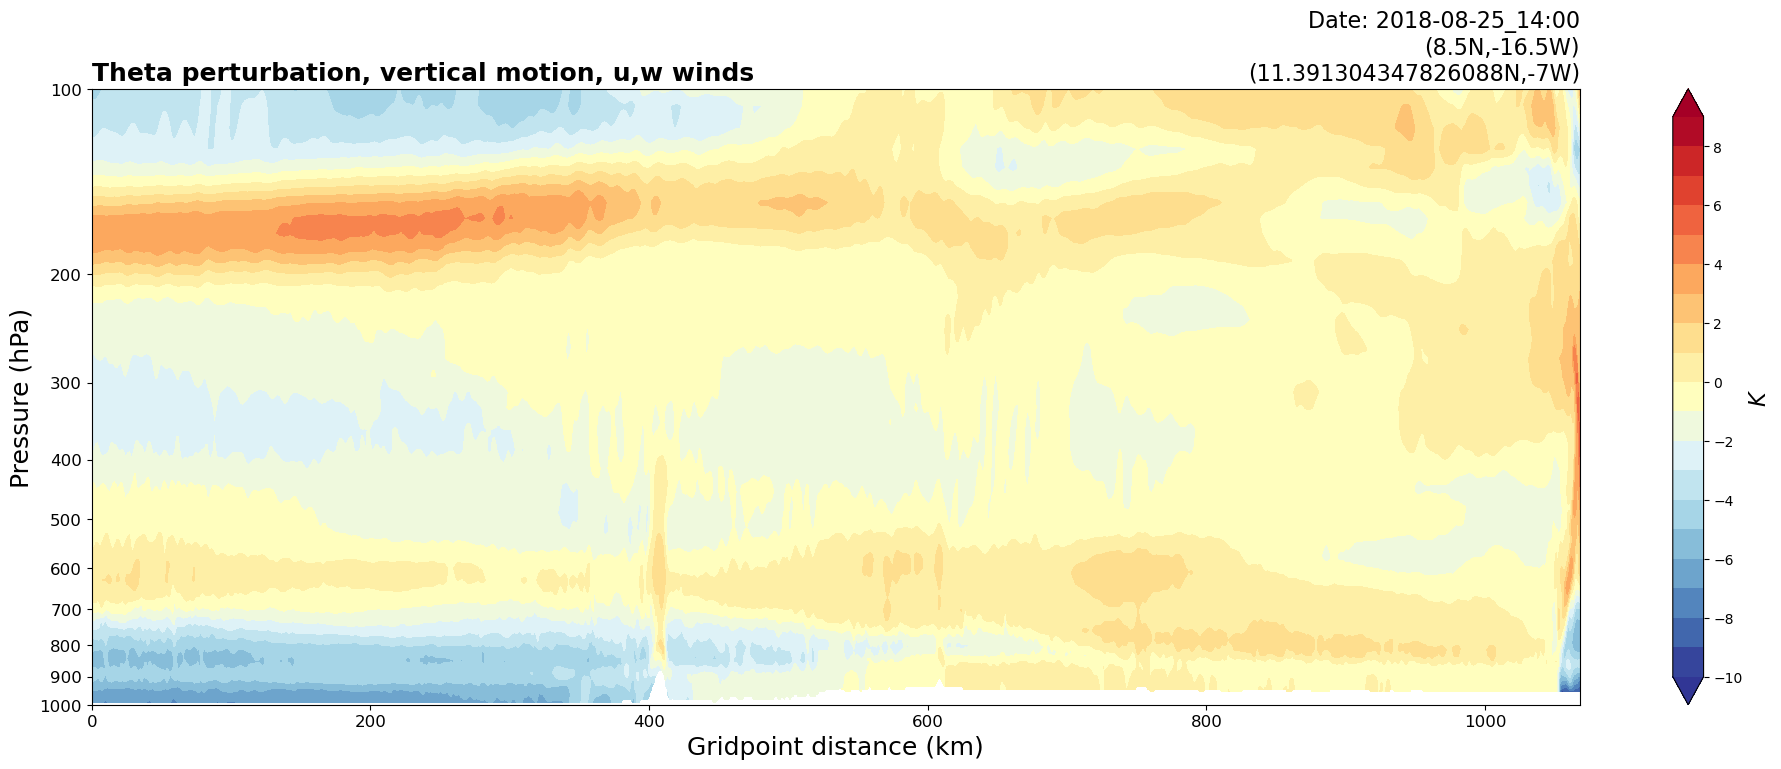

WRF valid time:  2018-08-25_14:30


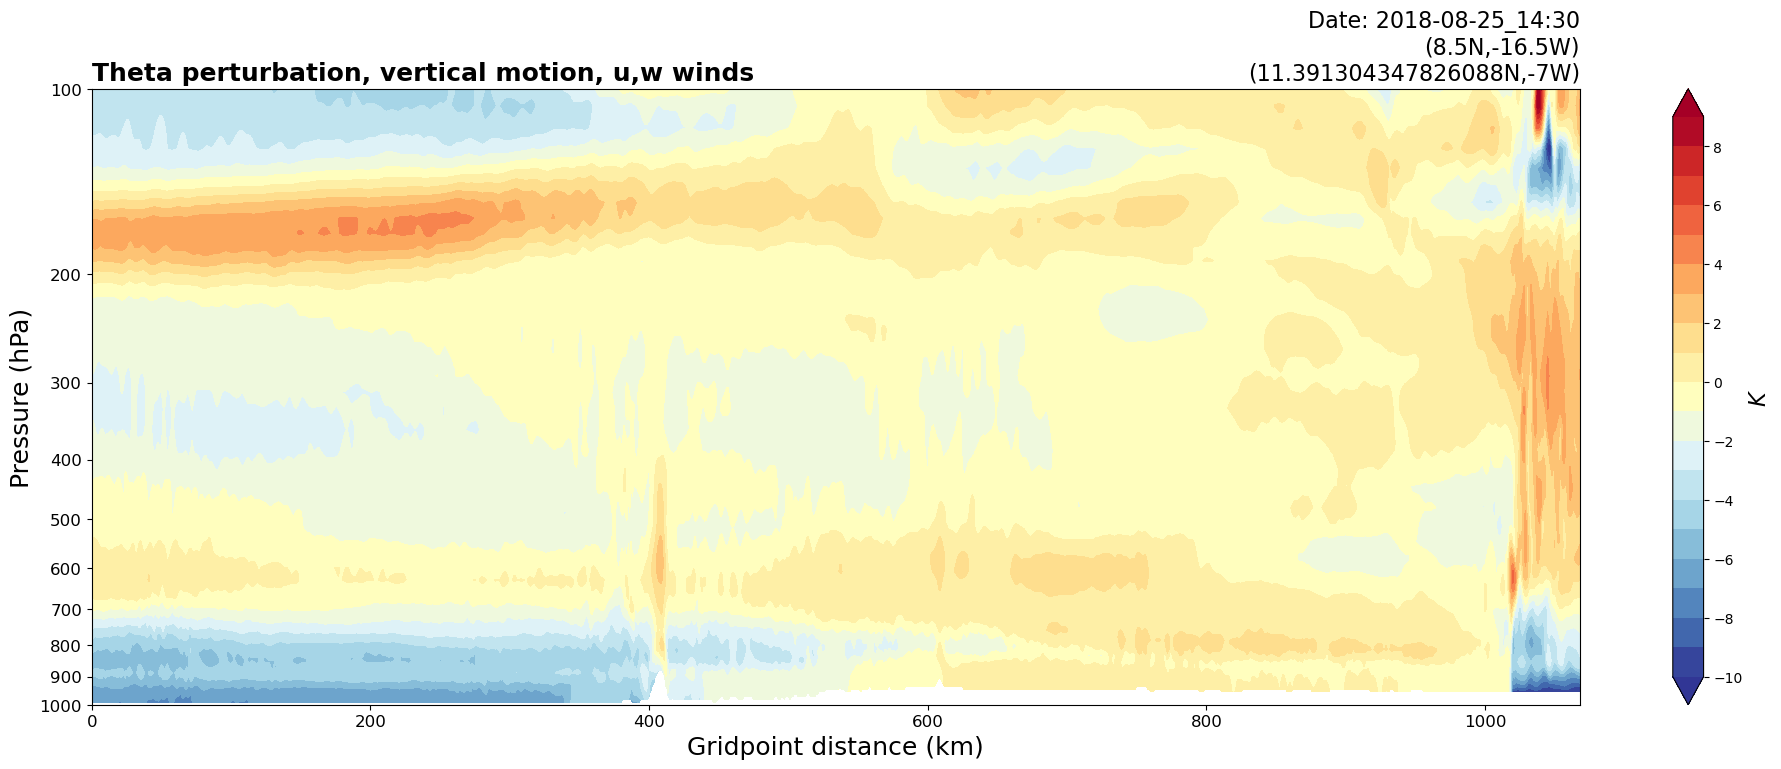

0
1053
2.1594405
1018
WRF valid time:  2018-08-25_15:00


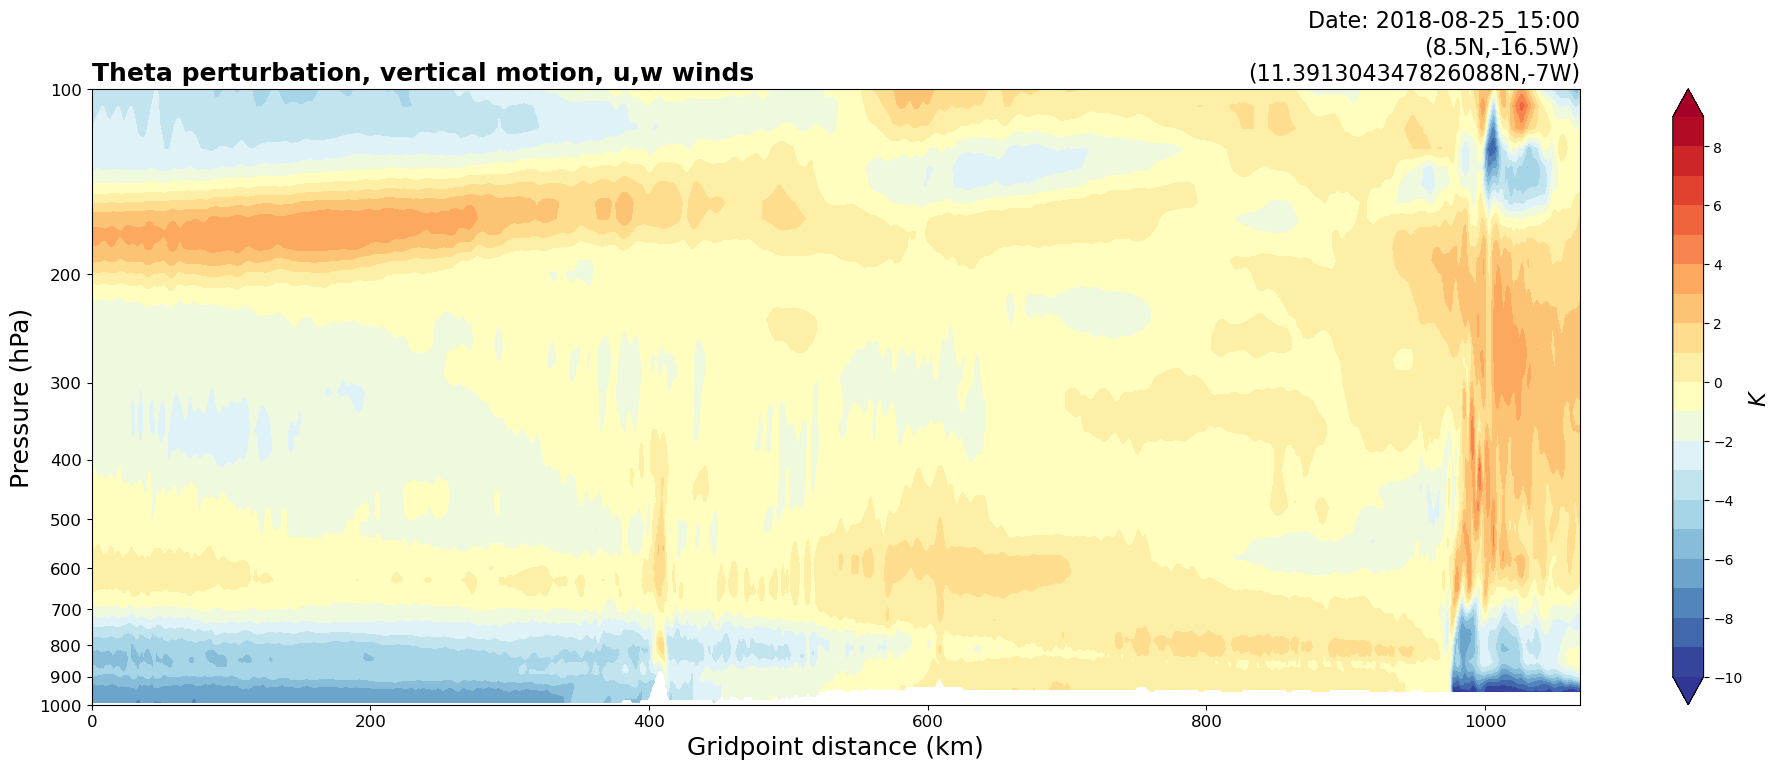

1
1018
2.467535
976
WRF valid time:  2018-08-25_15:30


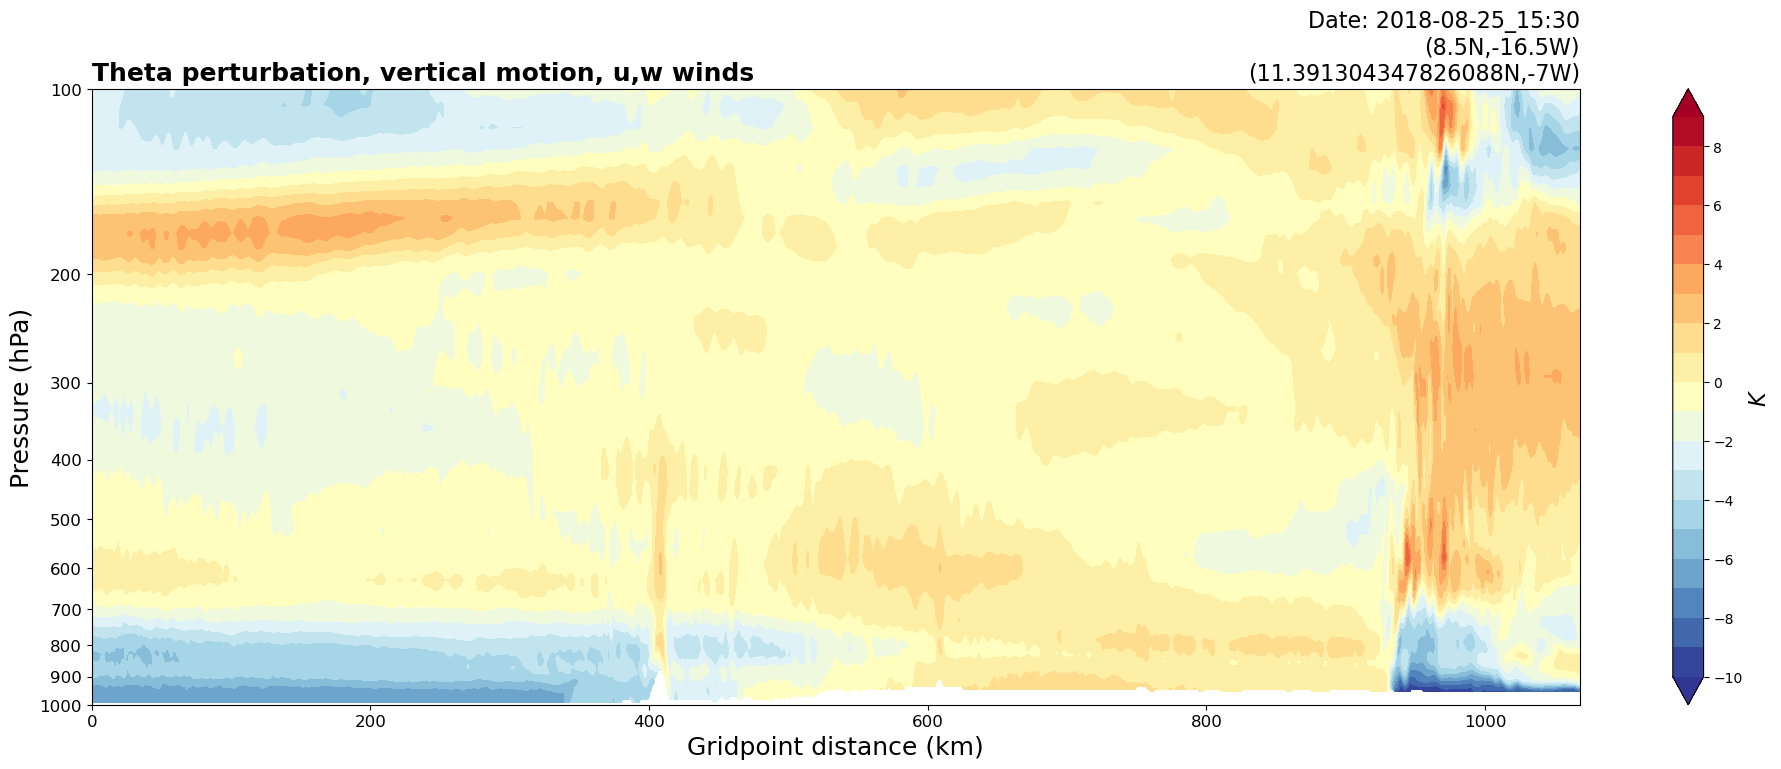

2
976
1.1174972
932
WRF valid time:  2018-08-25_16:00


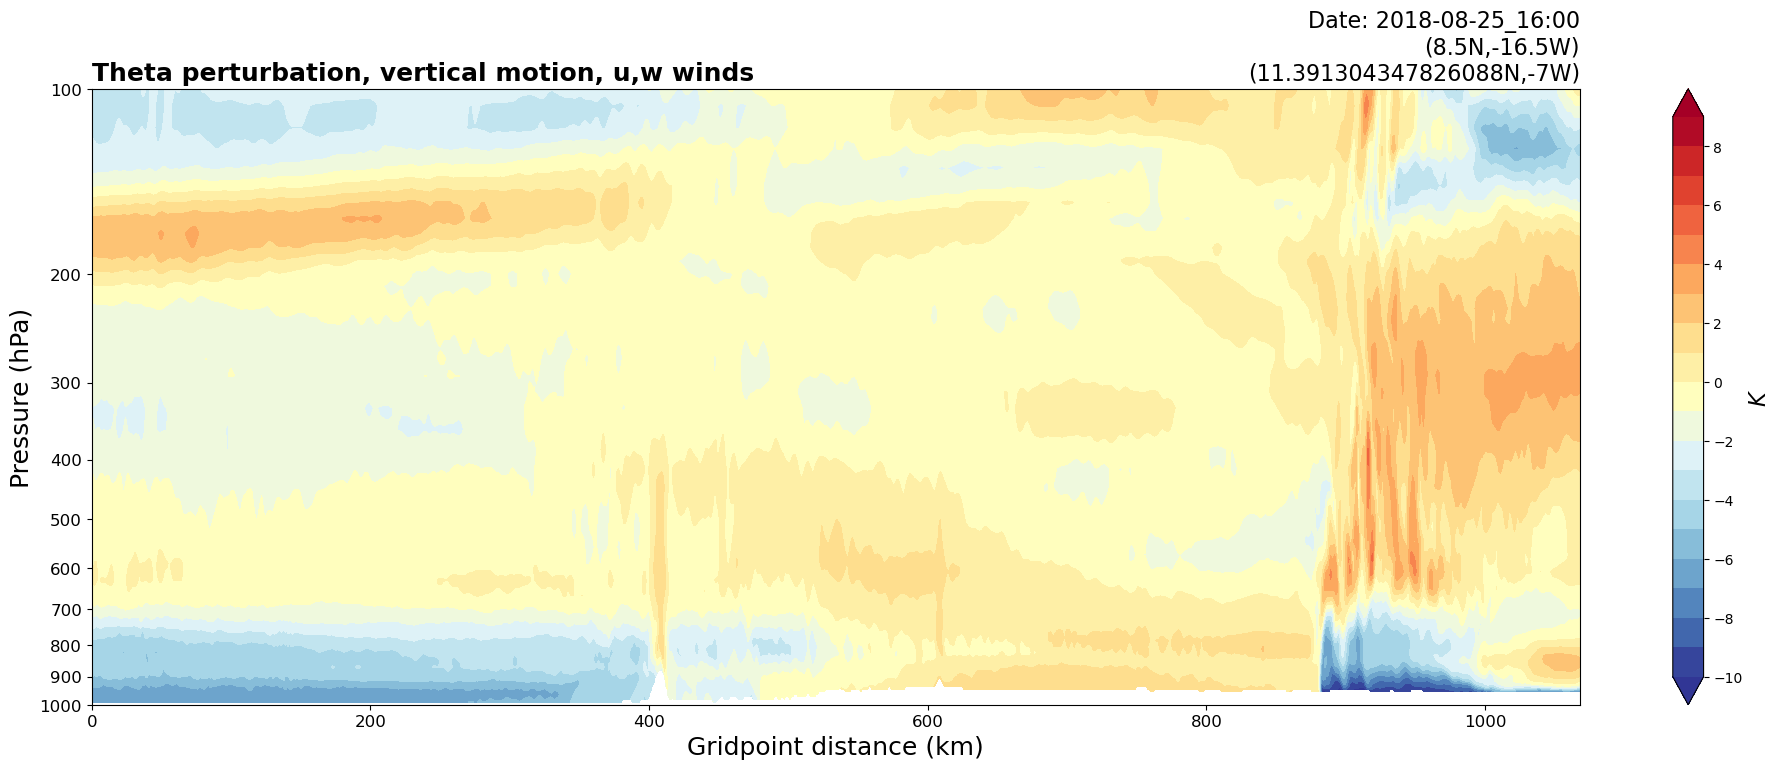

3
932
2.6058683
881
WRF valid time:  2018-08-25_16:30


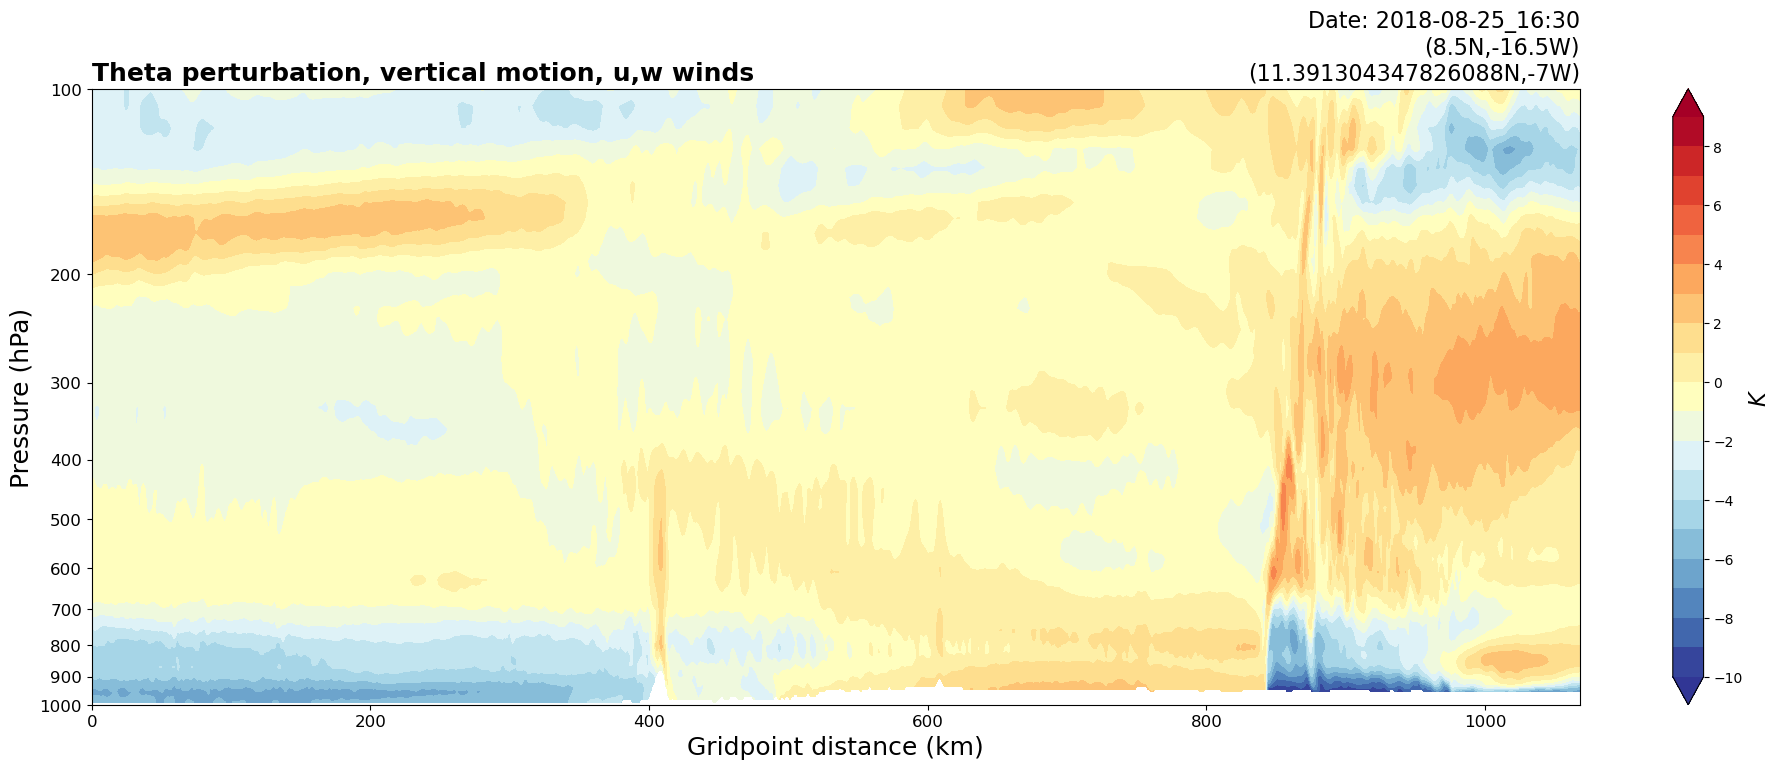

4
881
3.027918
843
WRF valid time:  2018-08-25_17:00


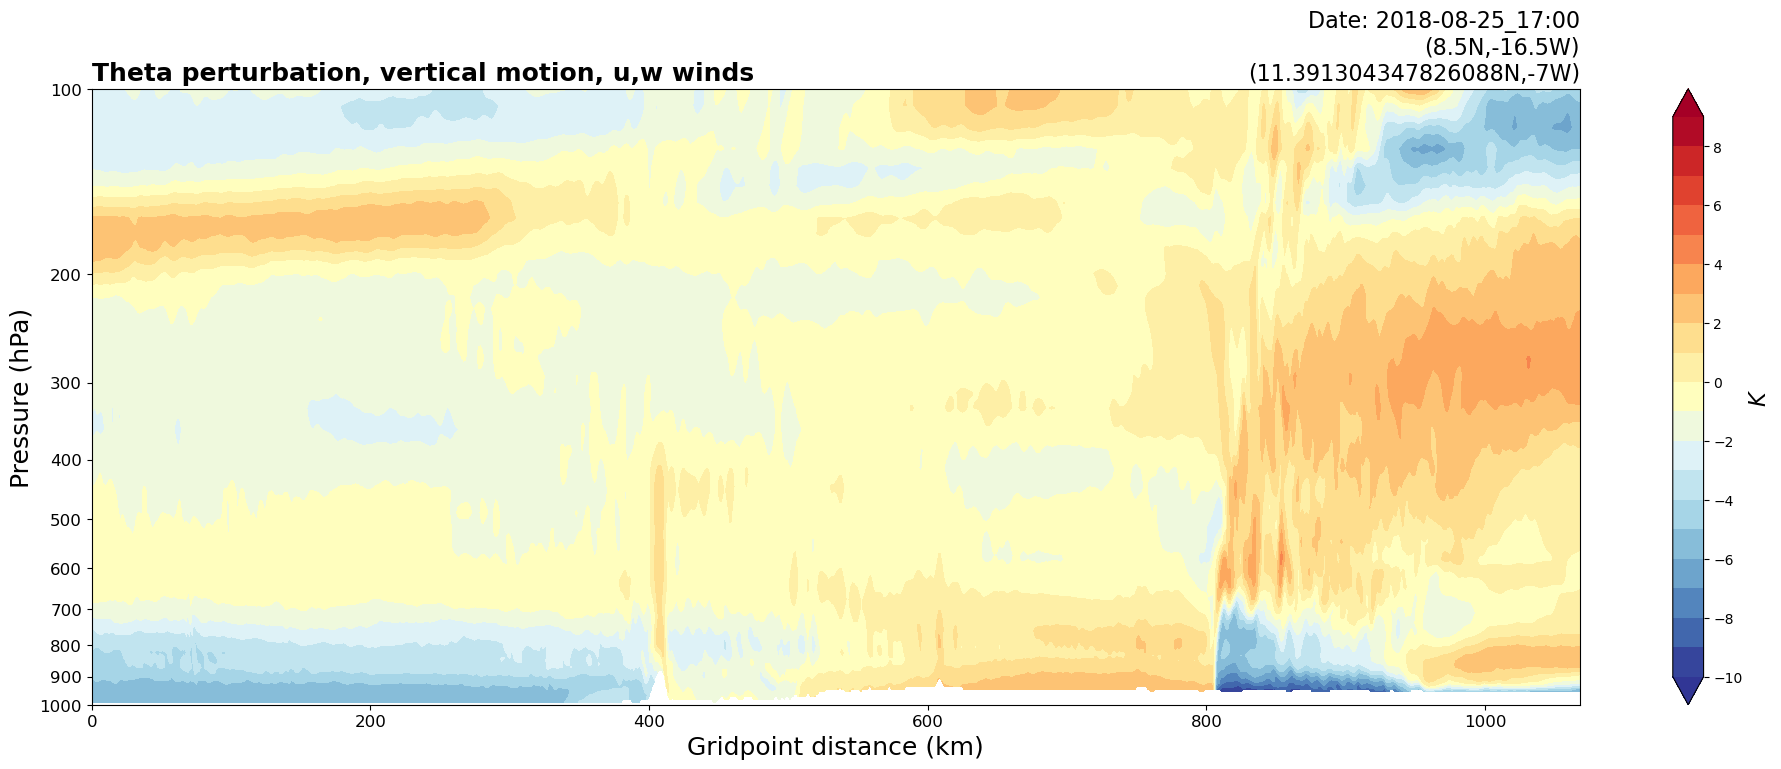

5
843
2.9082367
806
WRF valid time:  2018-08-25_17:30


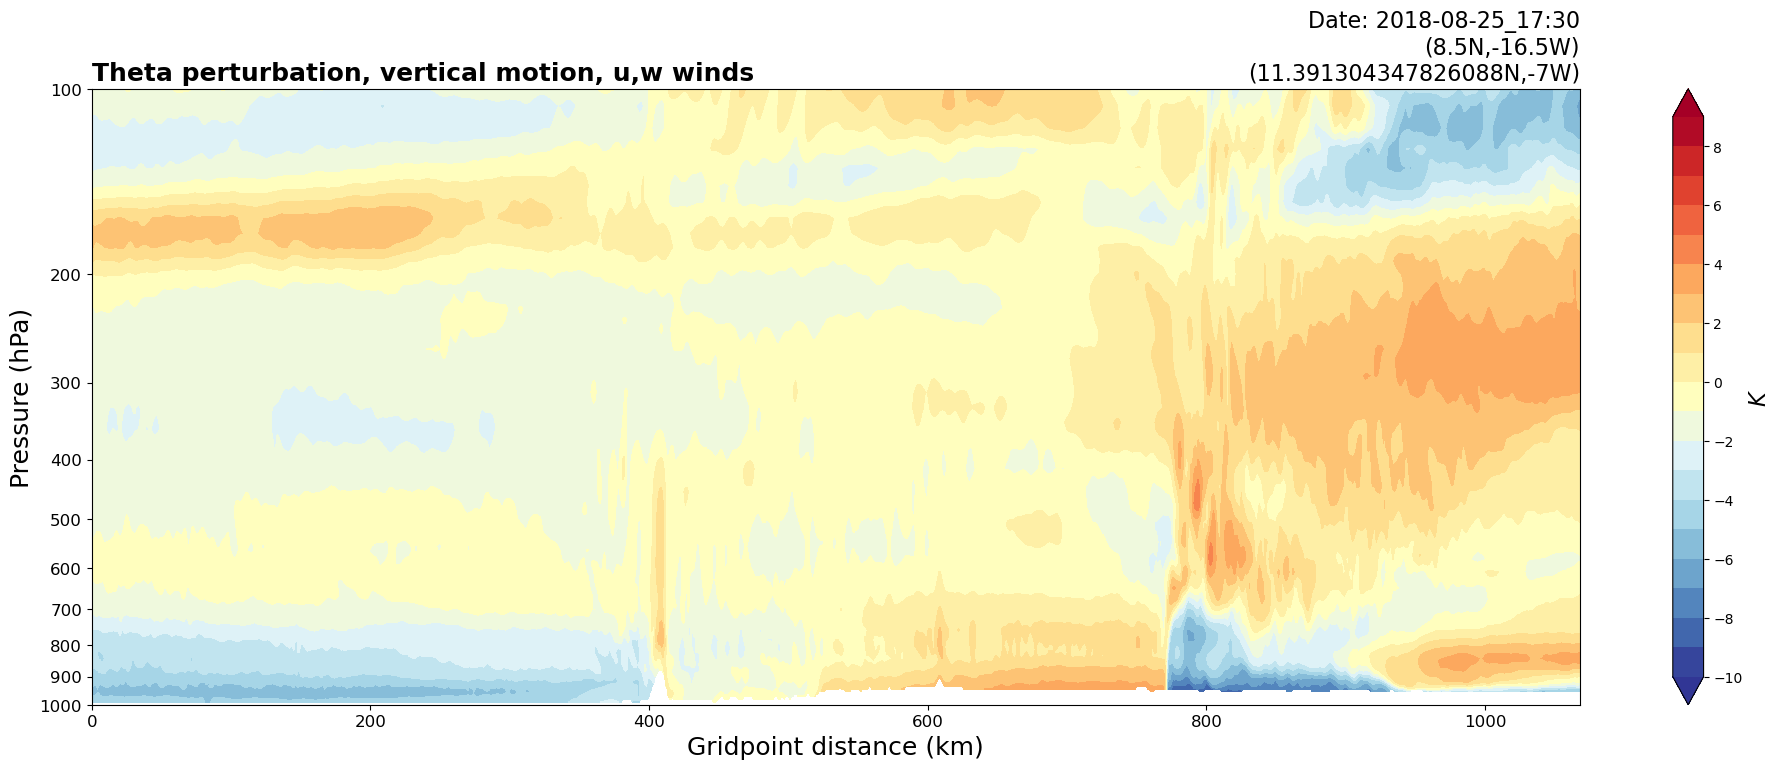

6
806
3.2665558
771
WRF valid time:  2018-08-25_18:00


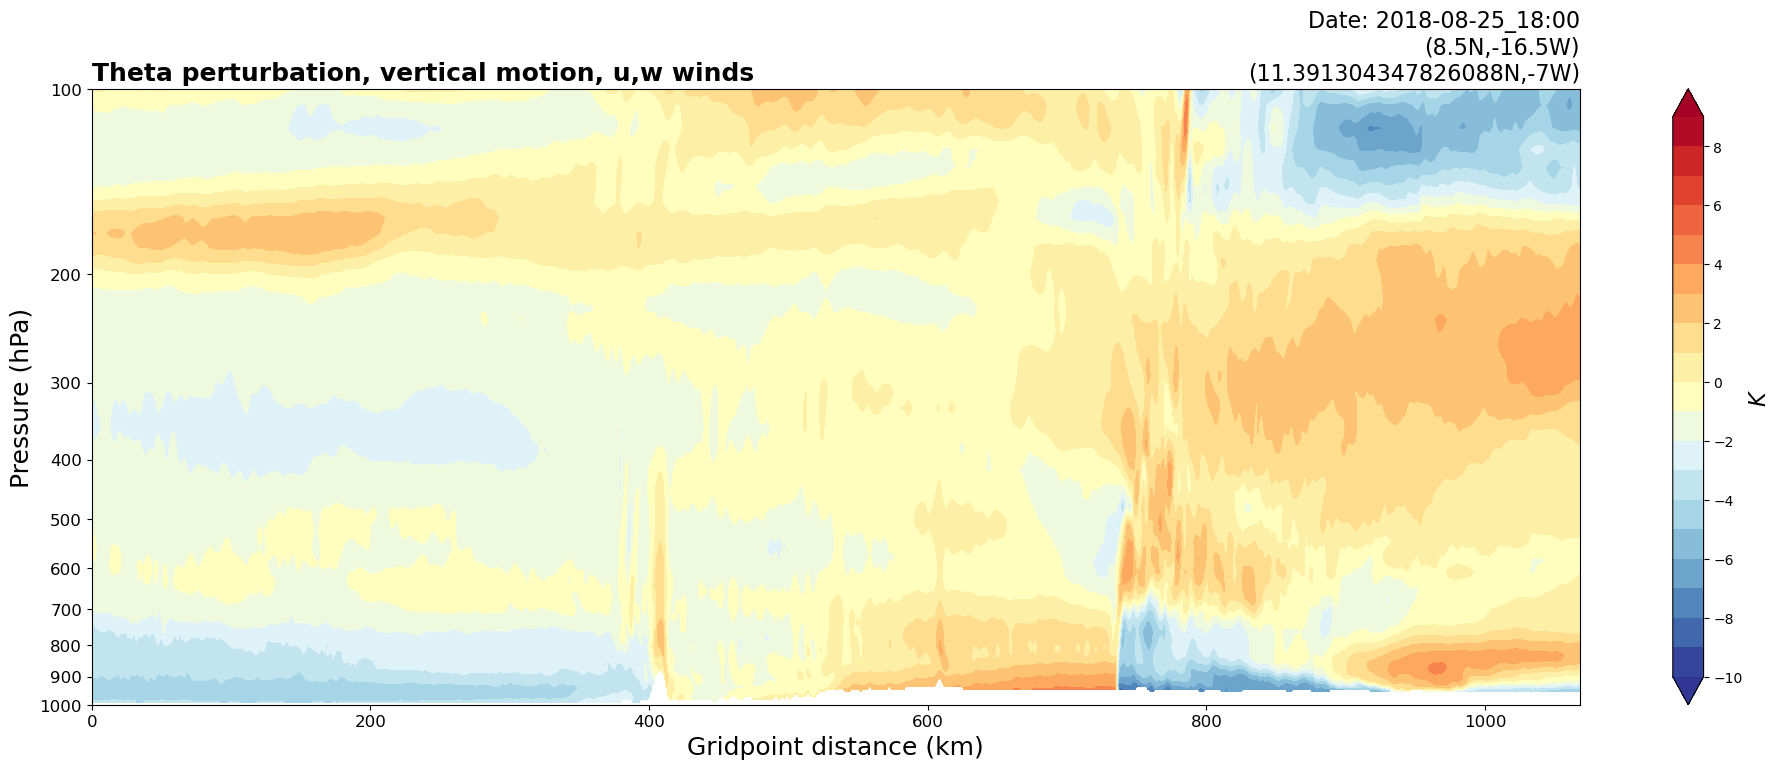

7
771
3.5236268
736
WRF valid time:  2018-08-25_18:30


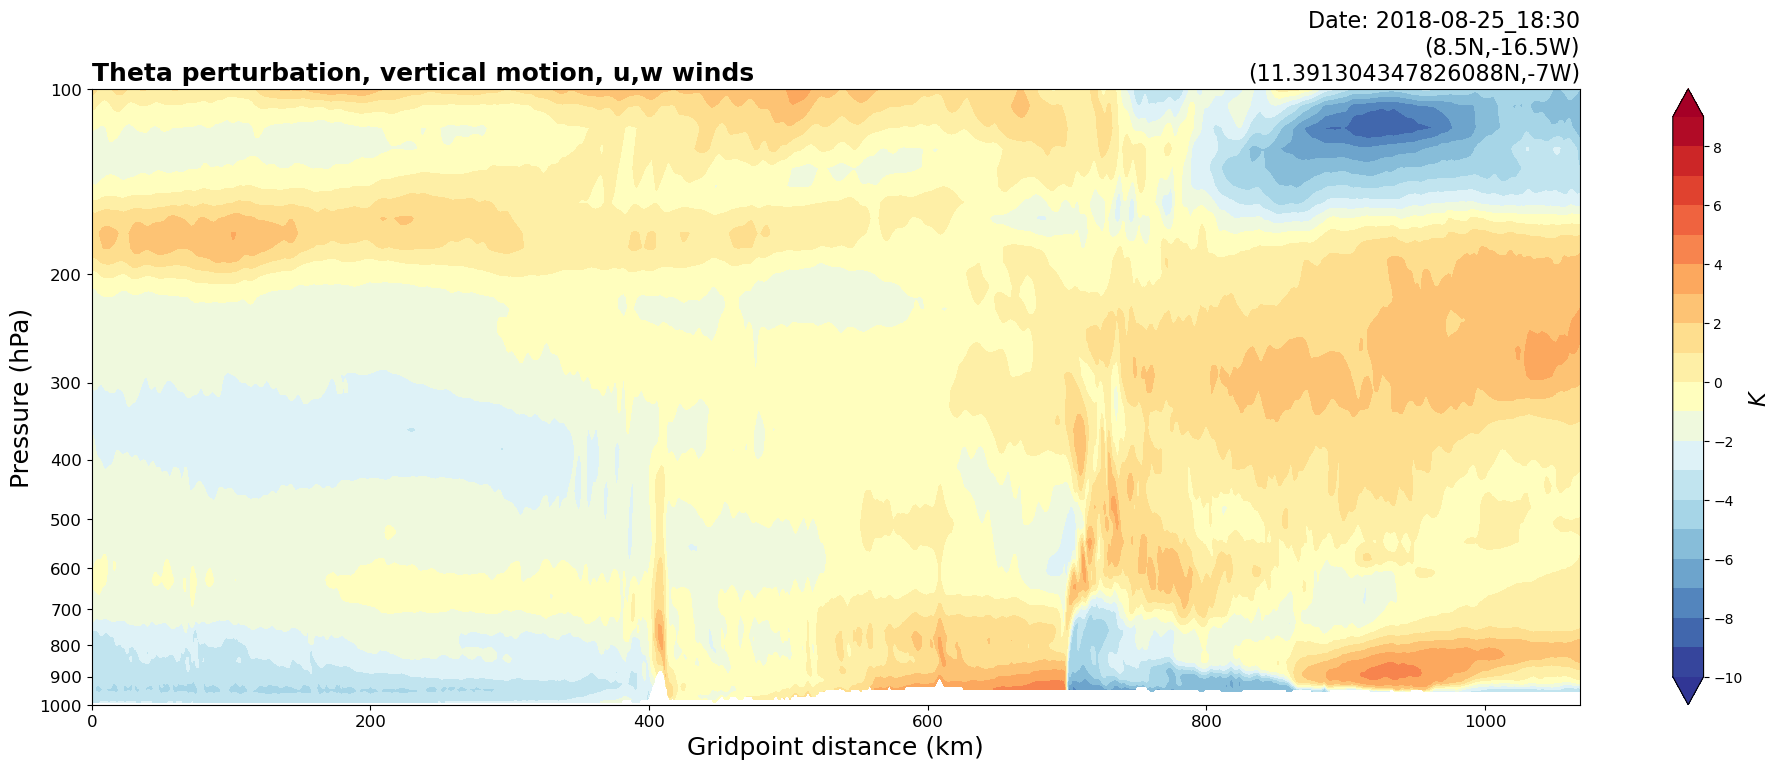

8
736
3.4789133
700
WRF valid time:  2018-08-25_19:00


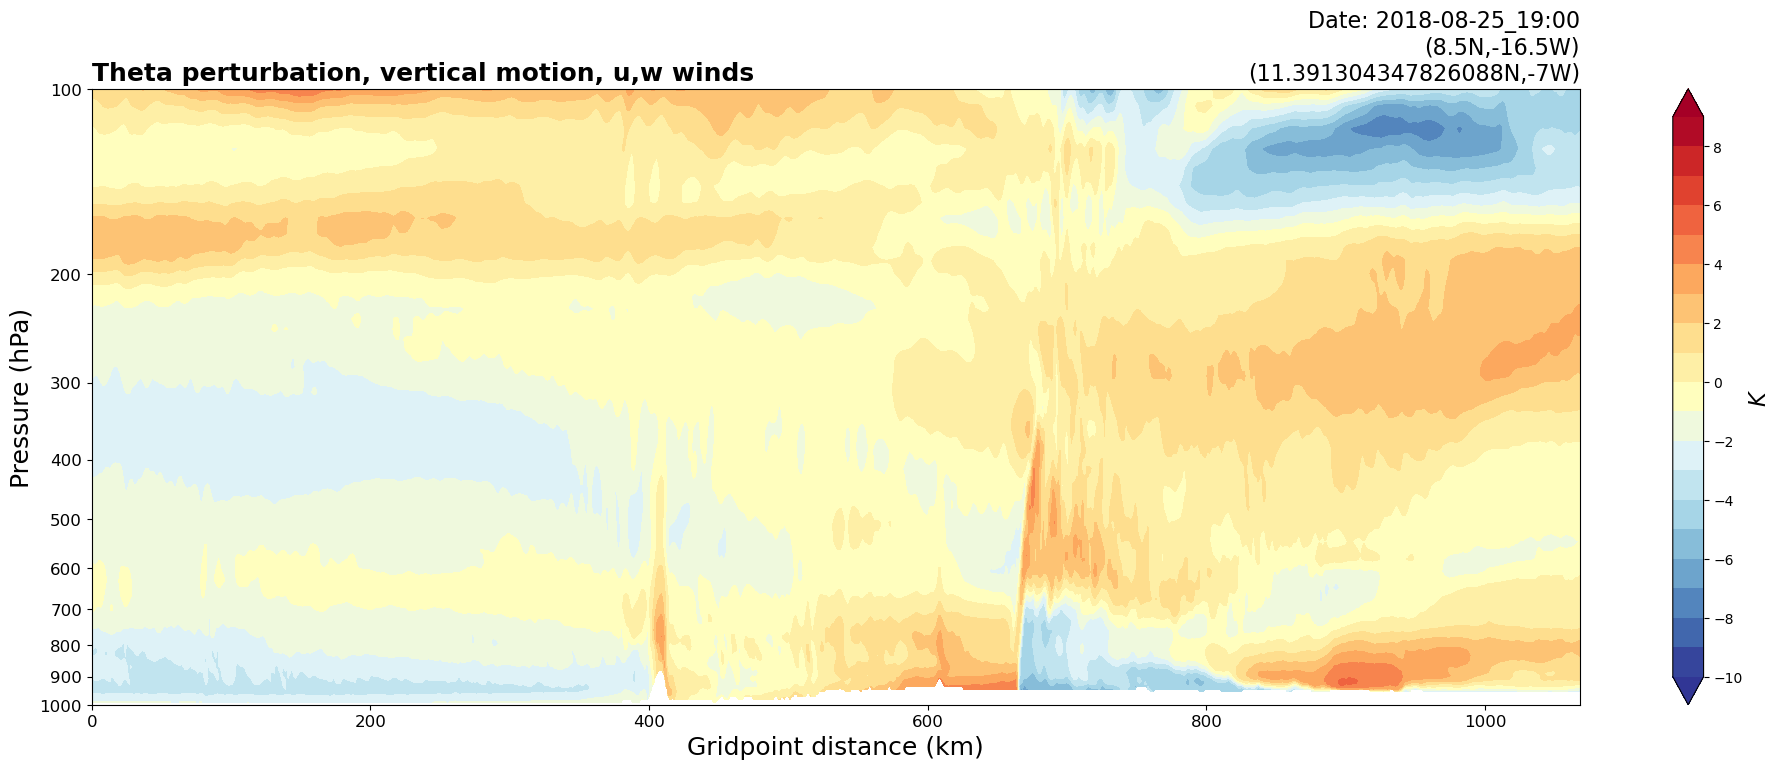

9
700
3.1078186
665
WRF valid time:  2018-08-25_19:30


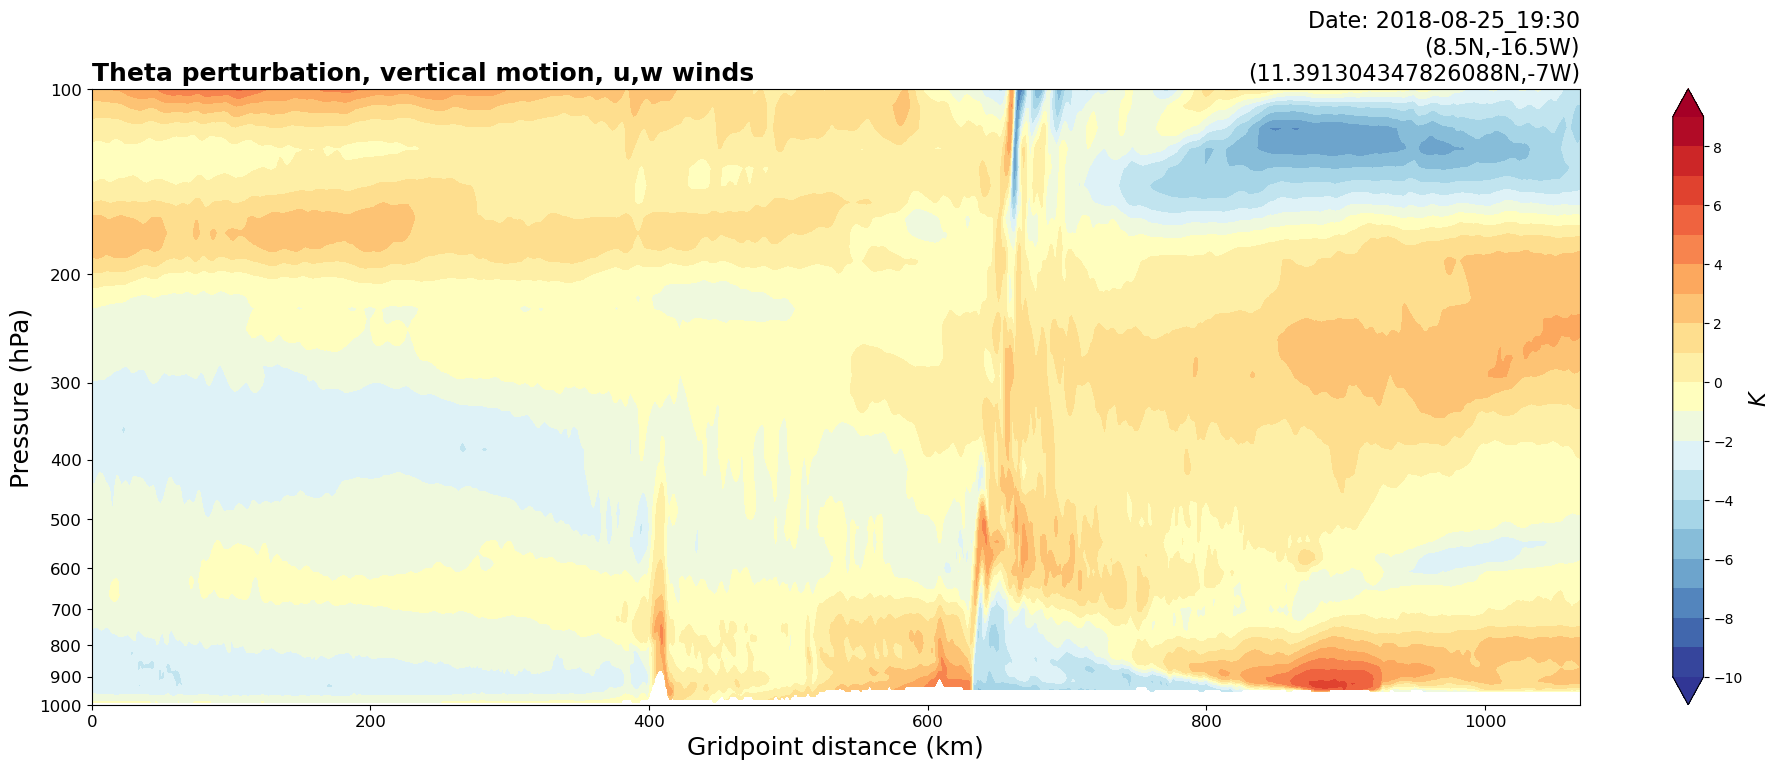

10
665
2.622728
632
WRF valid time:  2018-08-25_20:00


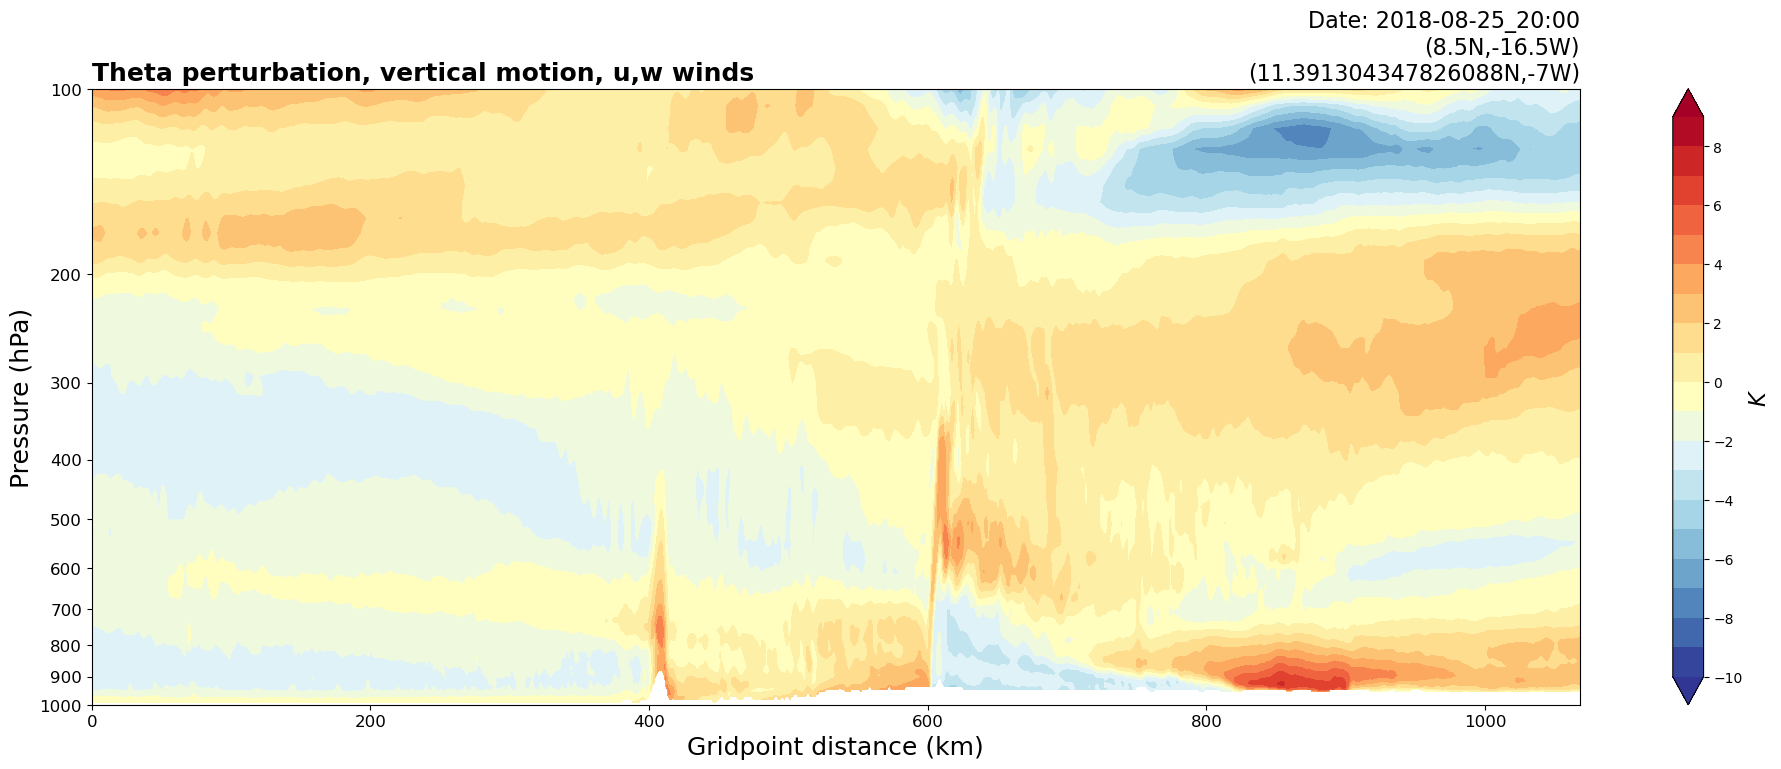

11
632
2.0441558
602
WRF valid time:  2018-08-25_20:30


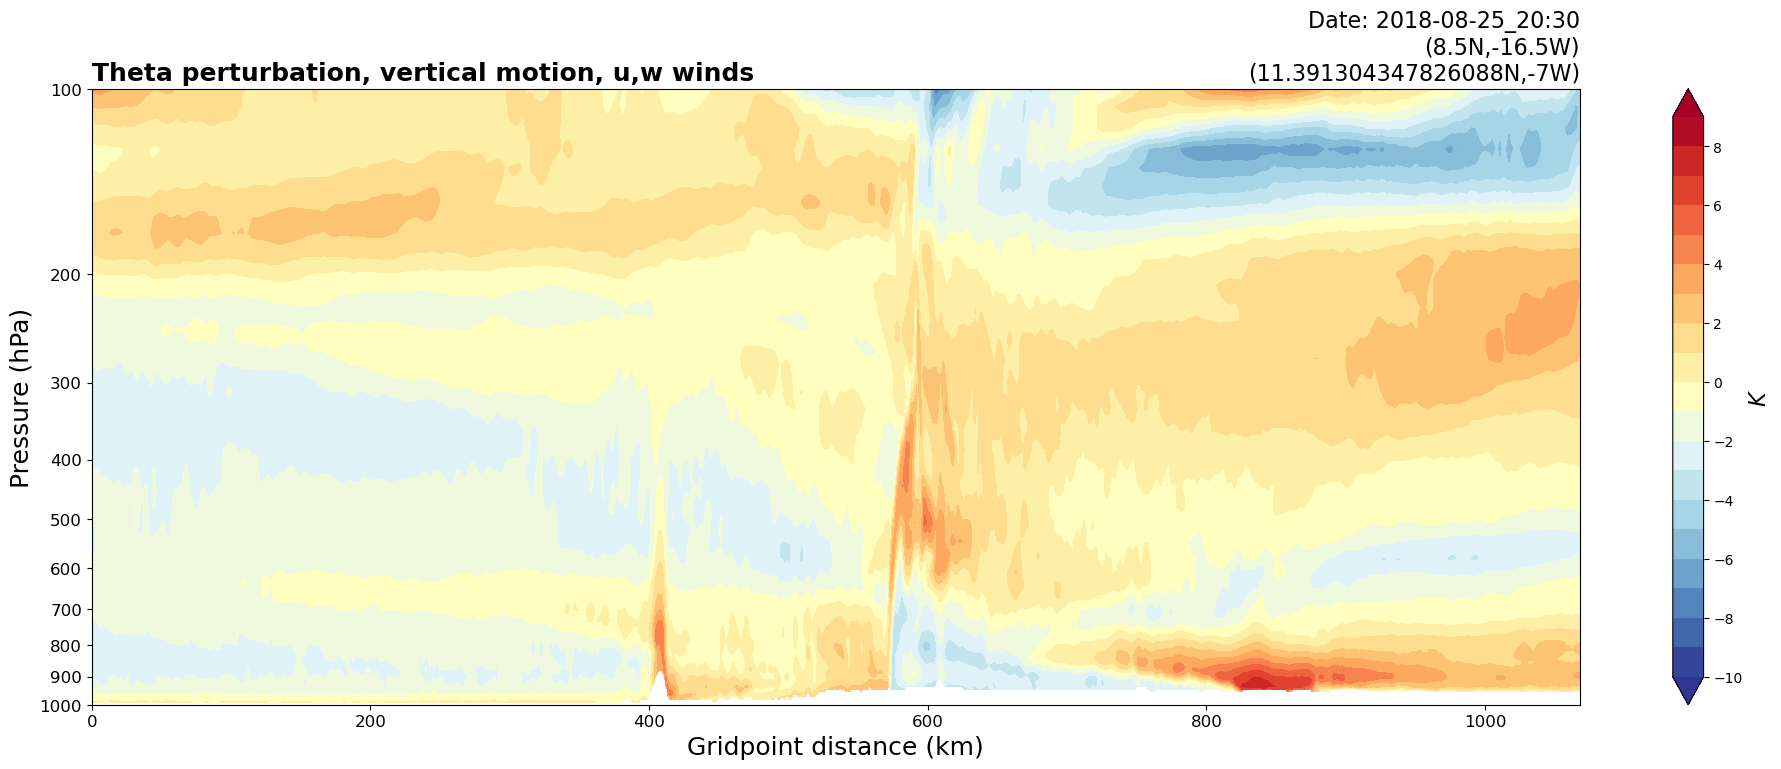

12
602
2.0106082
573
WRF valid time:  2018-08-25_21:00


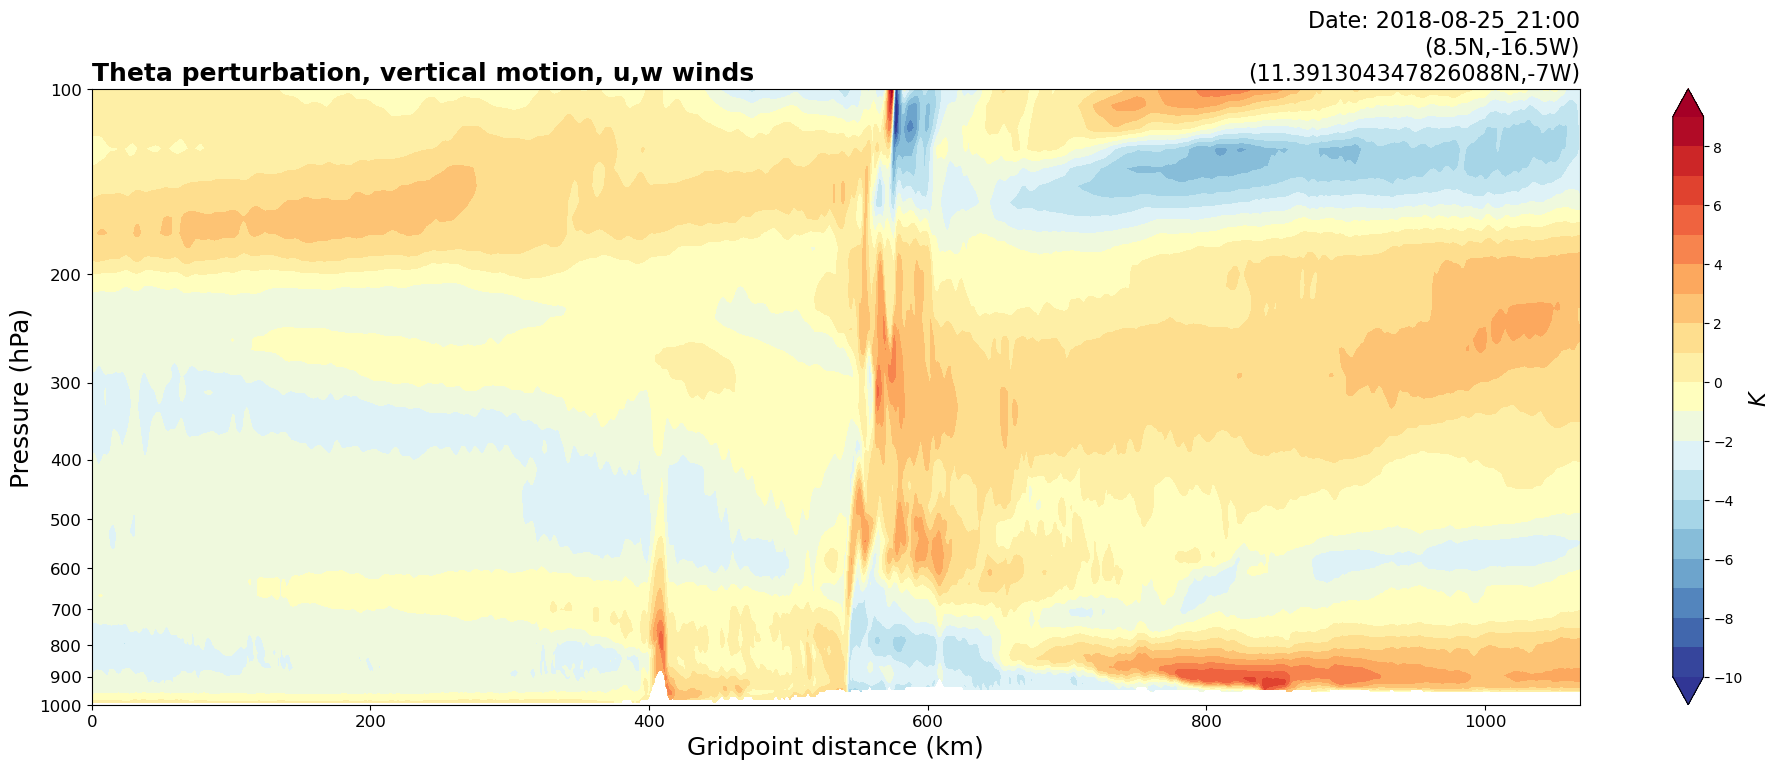

13
573
1.9633509
542
WRF valid time:  2018-08-25_21:30


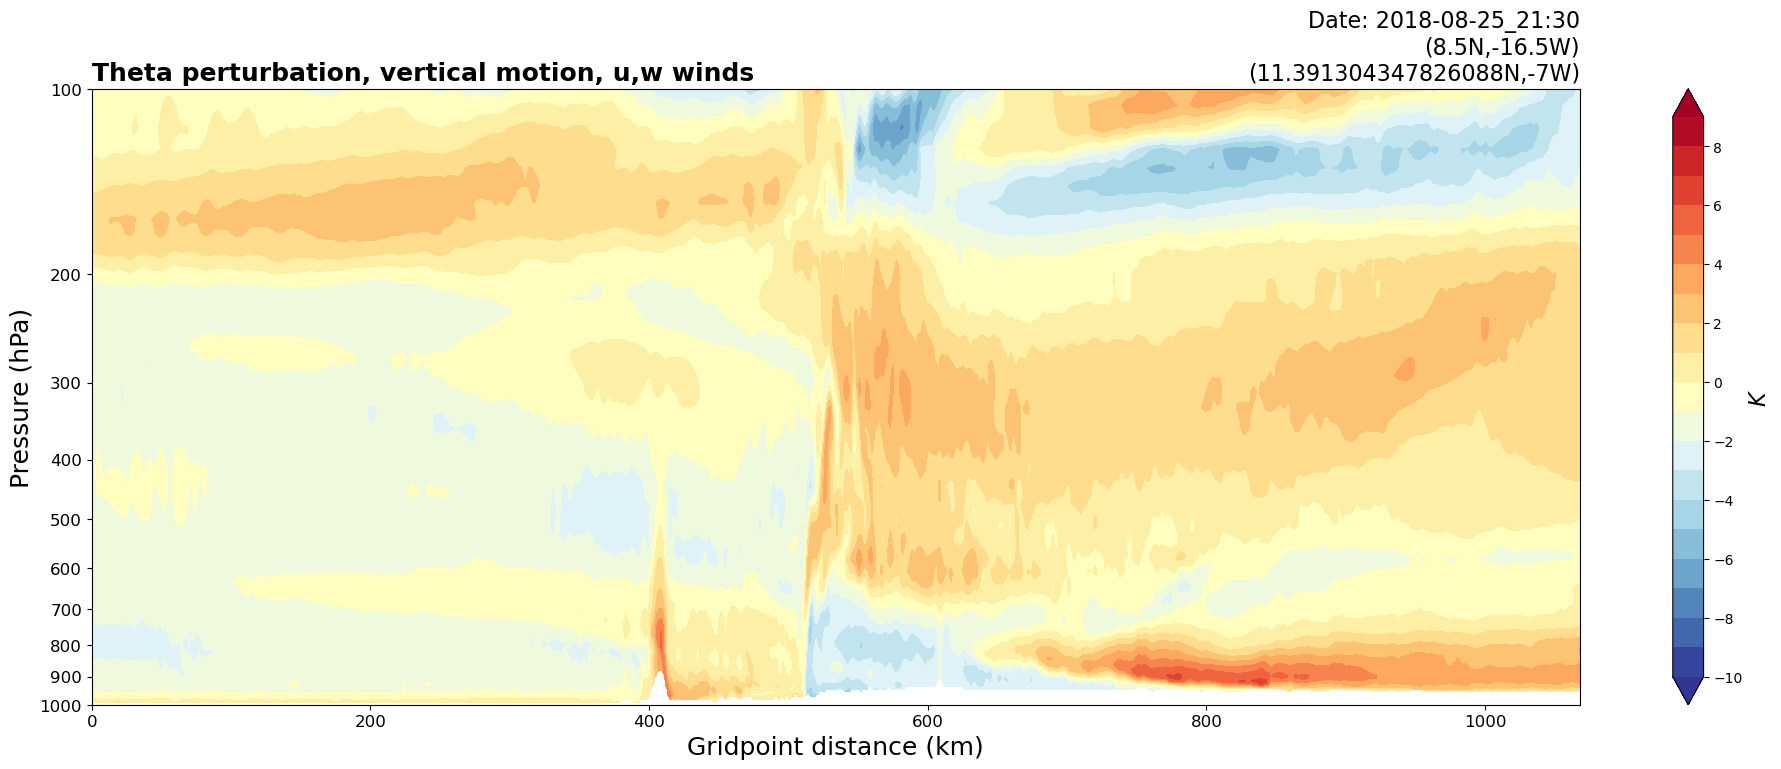

14
542
1.4304614
512
WRF valid time:  2018-08-25_22:00


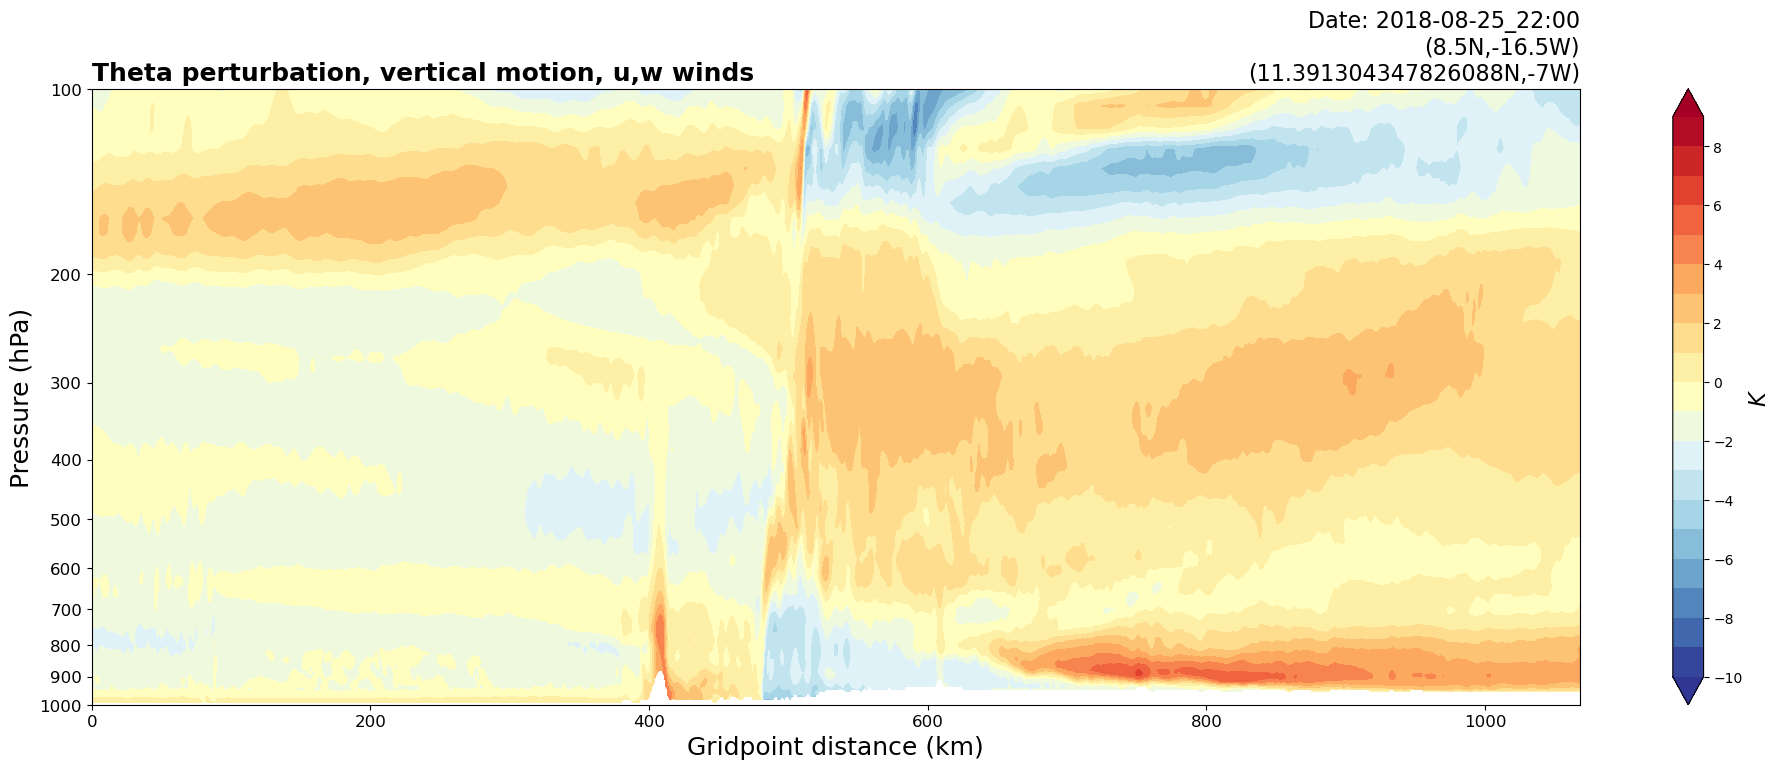

15
512
1.4475766
481
WRF valid time:  2018-08-25_22:30


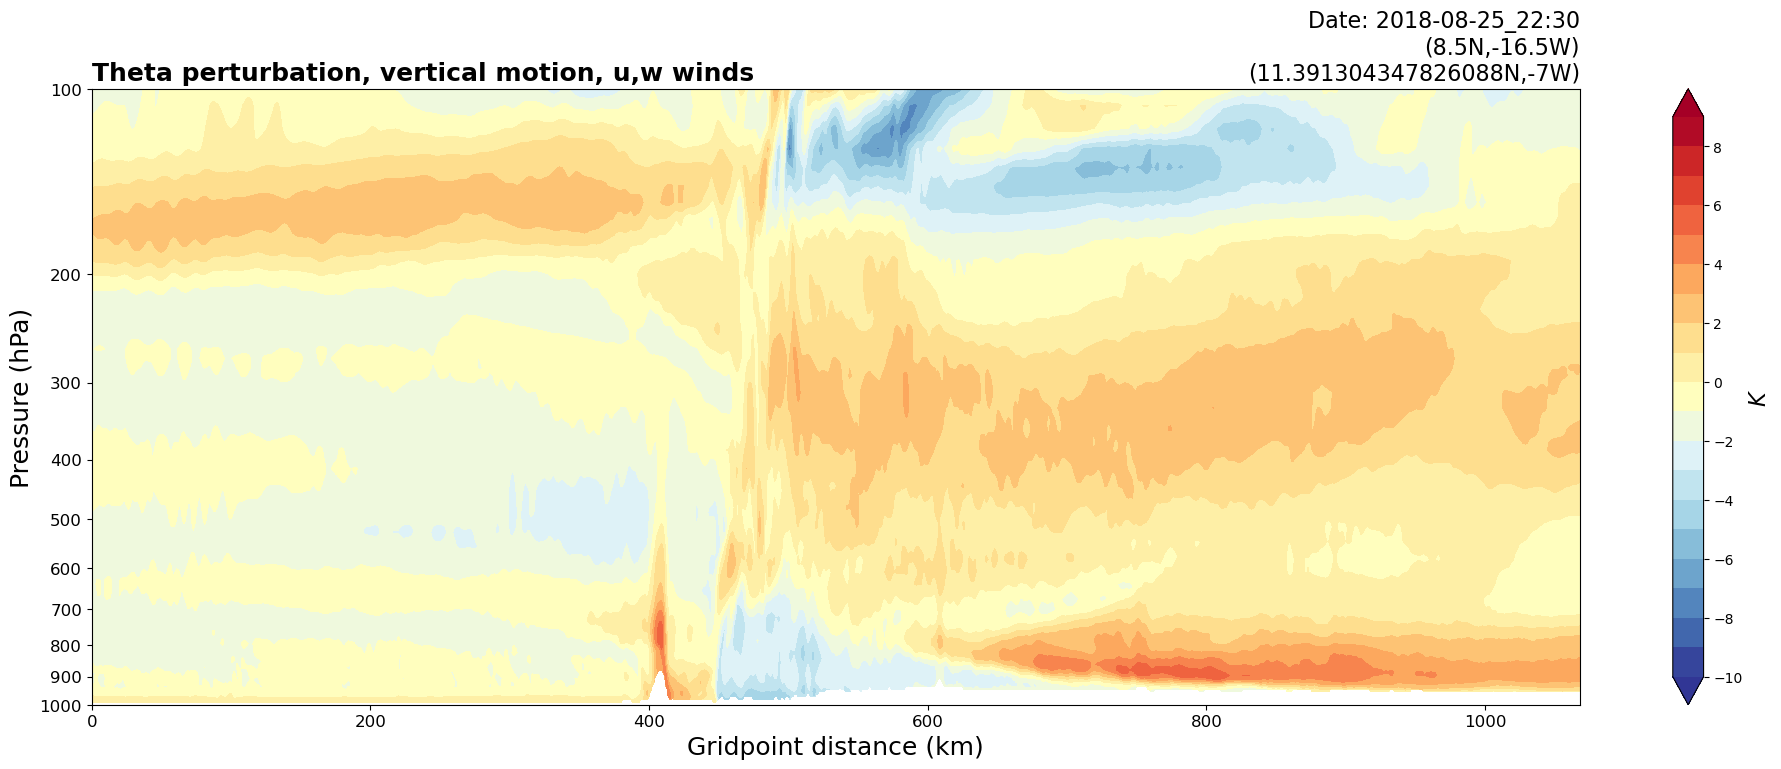

16
481
1.1876099
448
WRF valid time:  2018-08-25_23:00


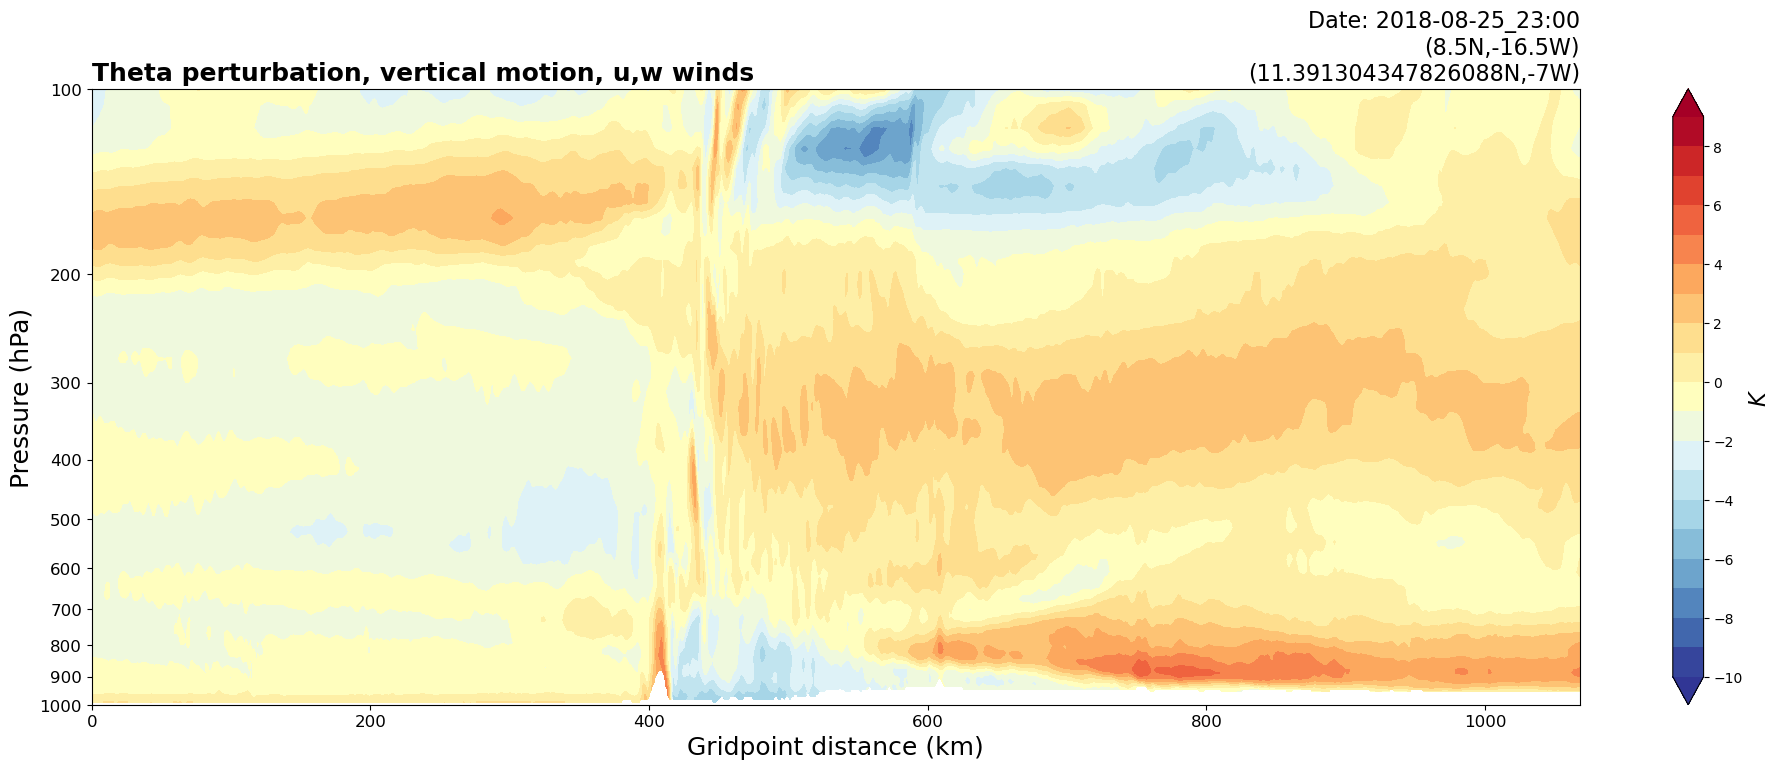

17
448
1.8902678
415
WRF valid time:  2018-08-25_23:30


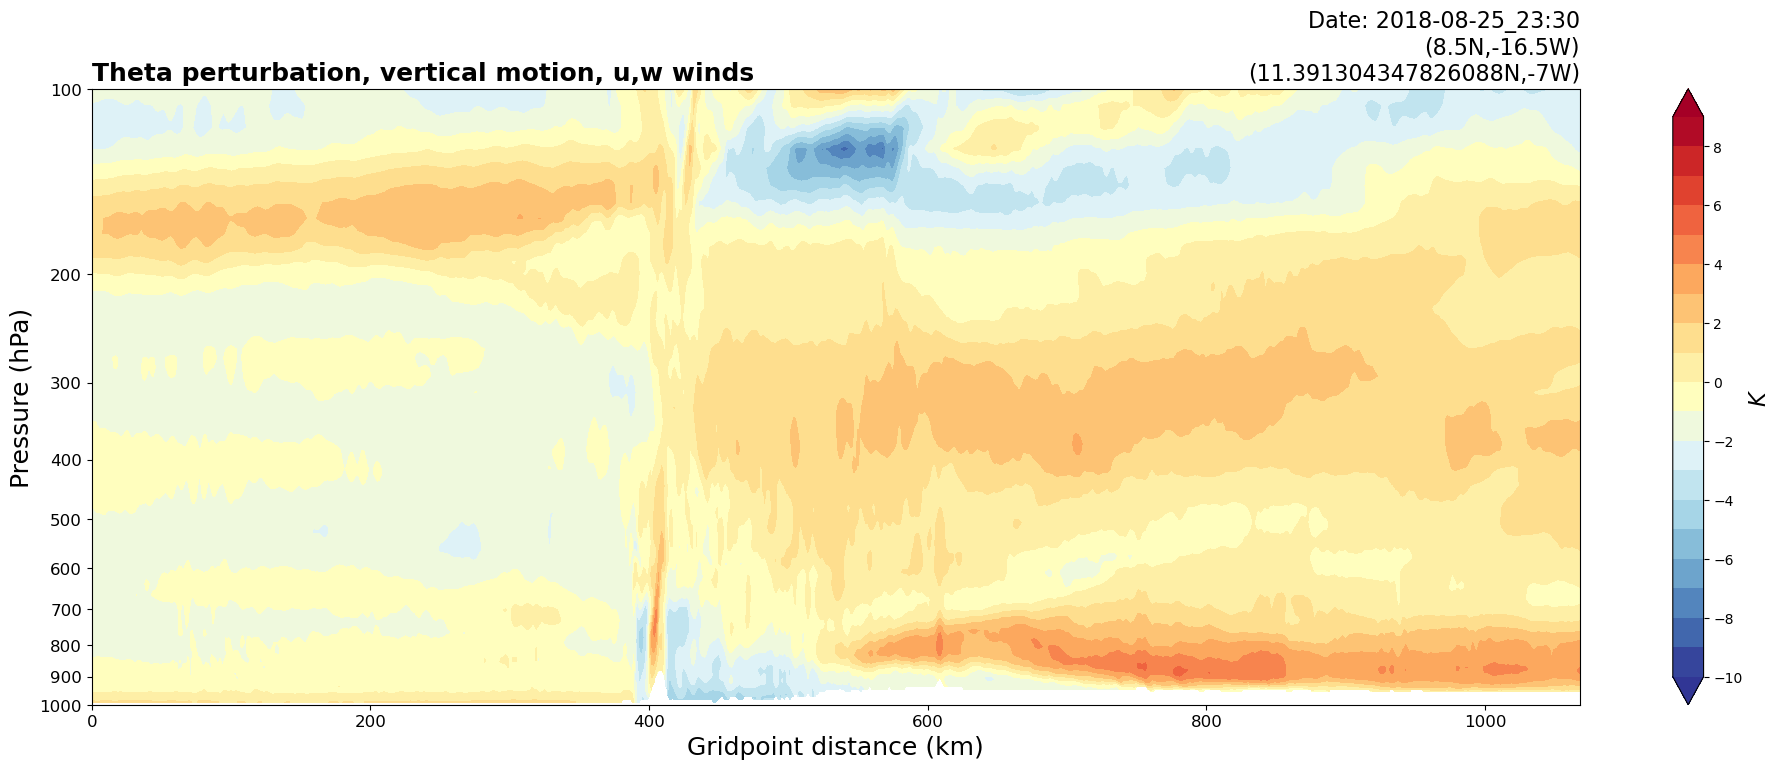

18
415
1.1295643
400
WRF valid time:  2018-08-26_00:00


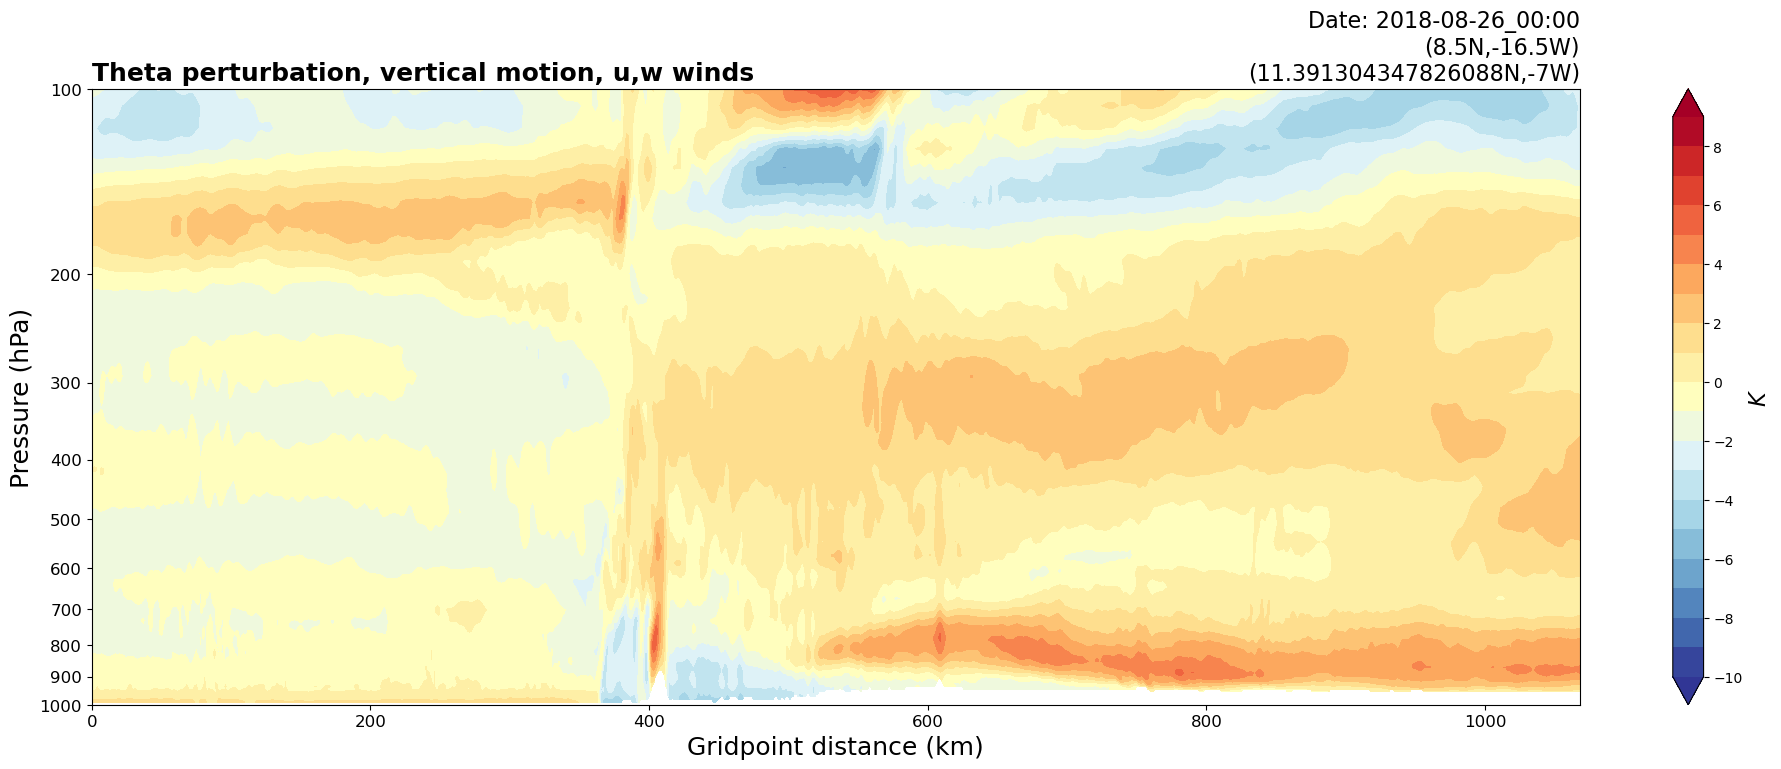

19
400
0.92926455
365
WRF valid time:  2018-08-26_00:30


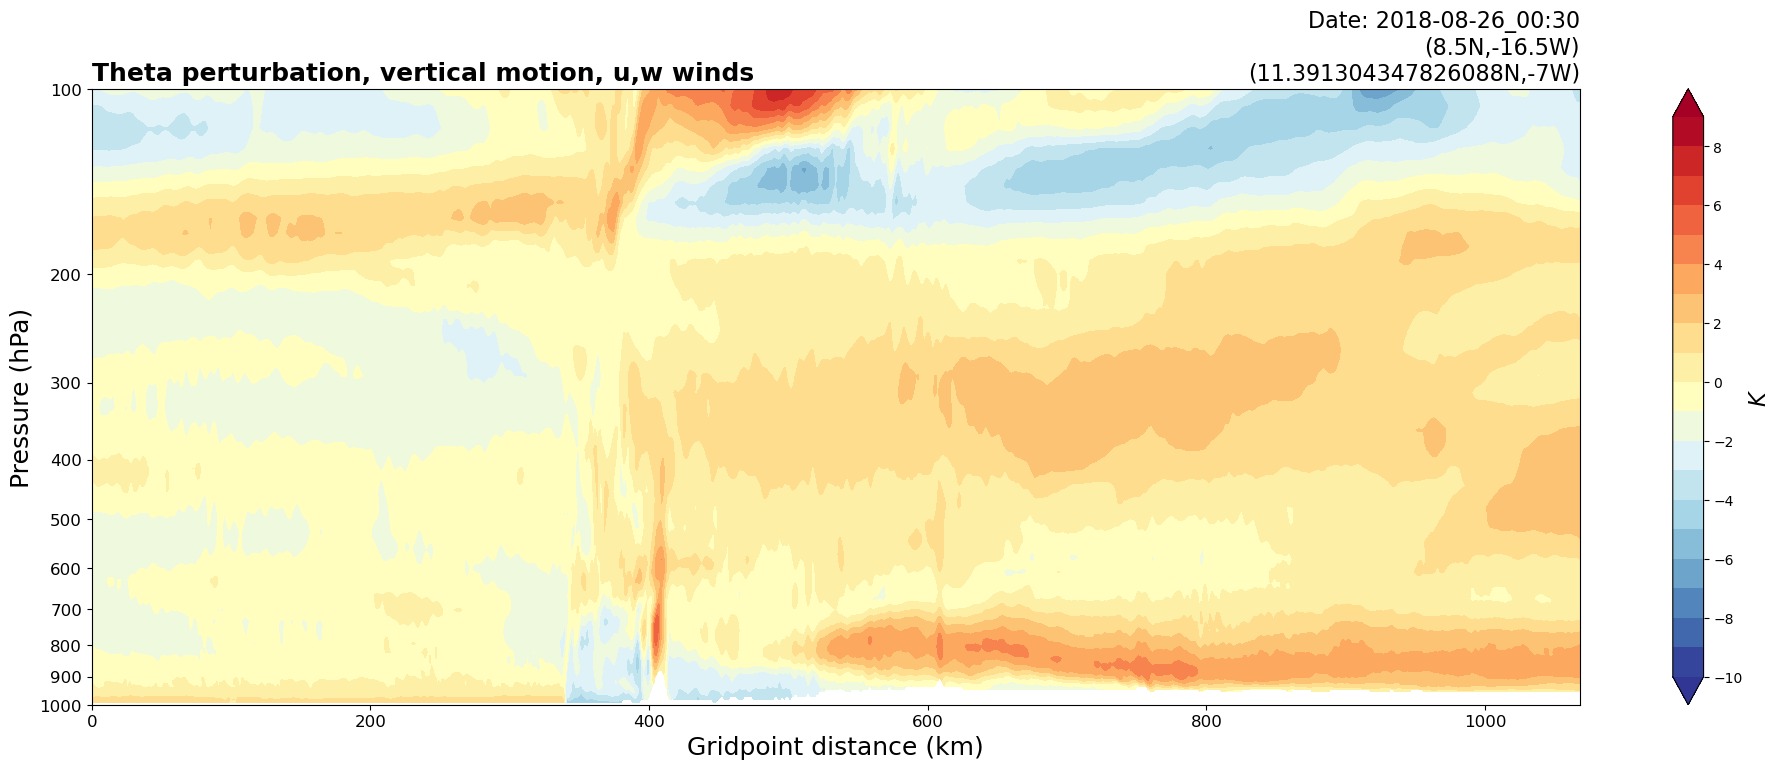

20
365
1.091805
340
WRF valid time:  2018-08-26_01:00


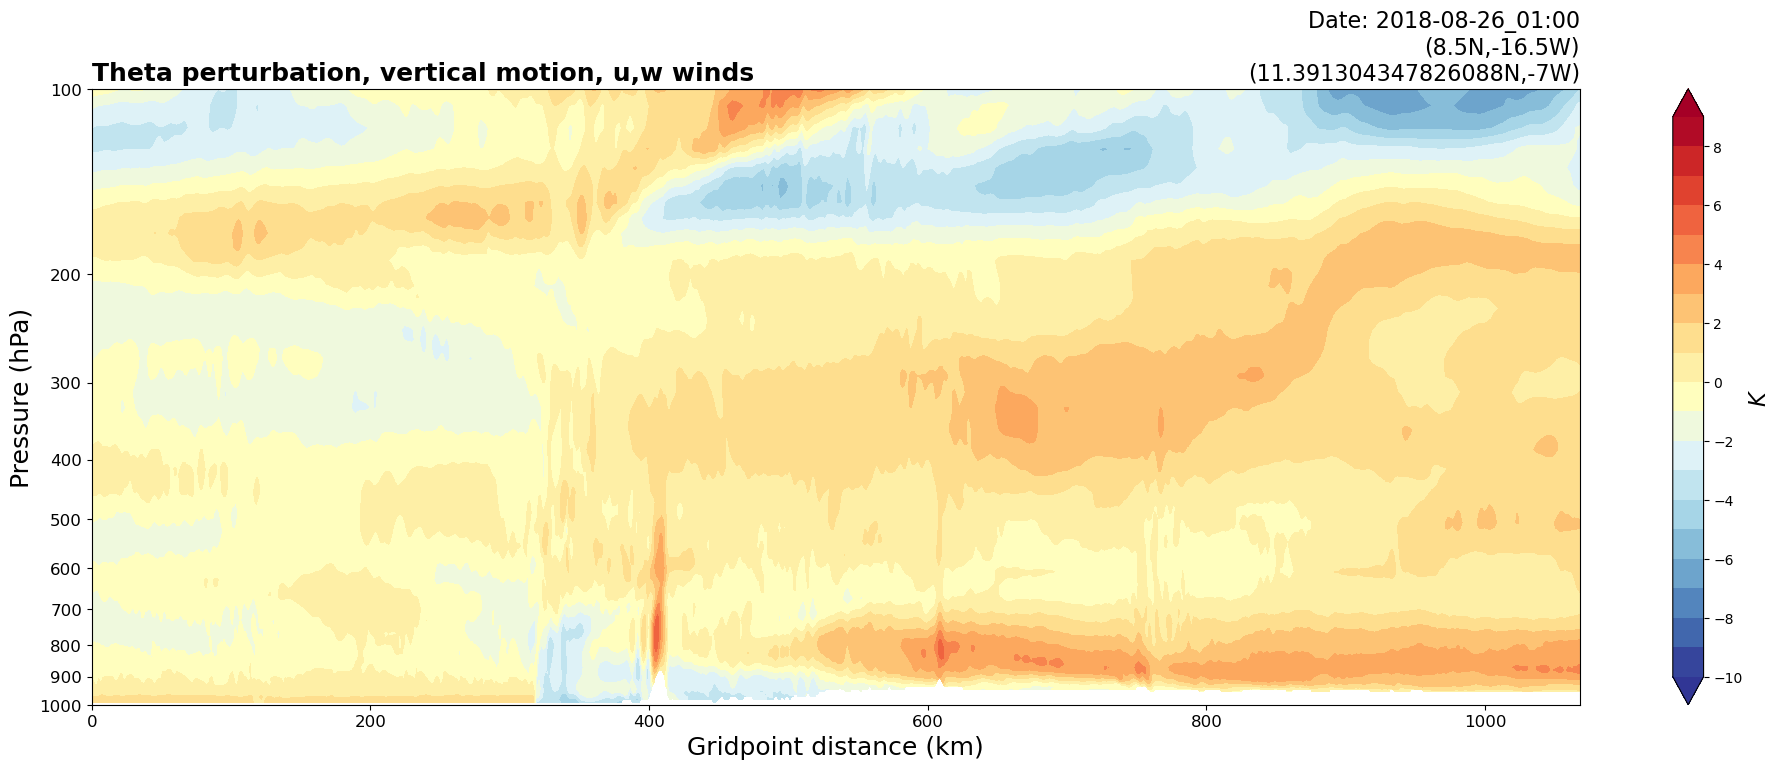

21
340
0.78979594
319
WRF valid time:  2018-08-26_01:30


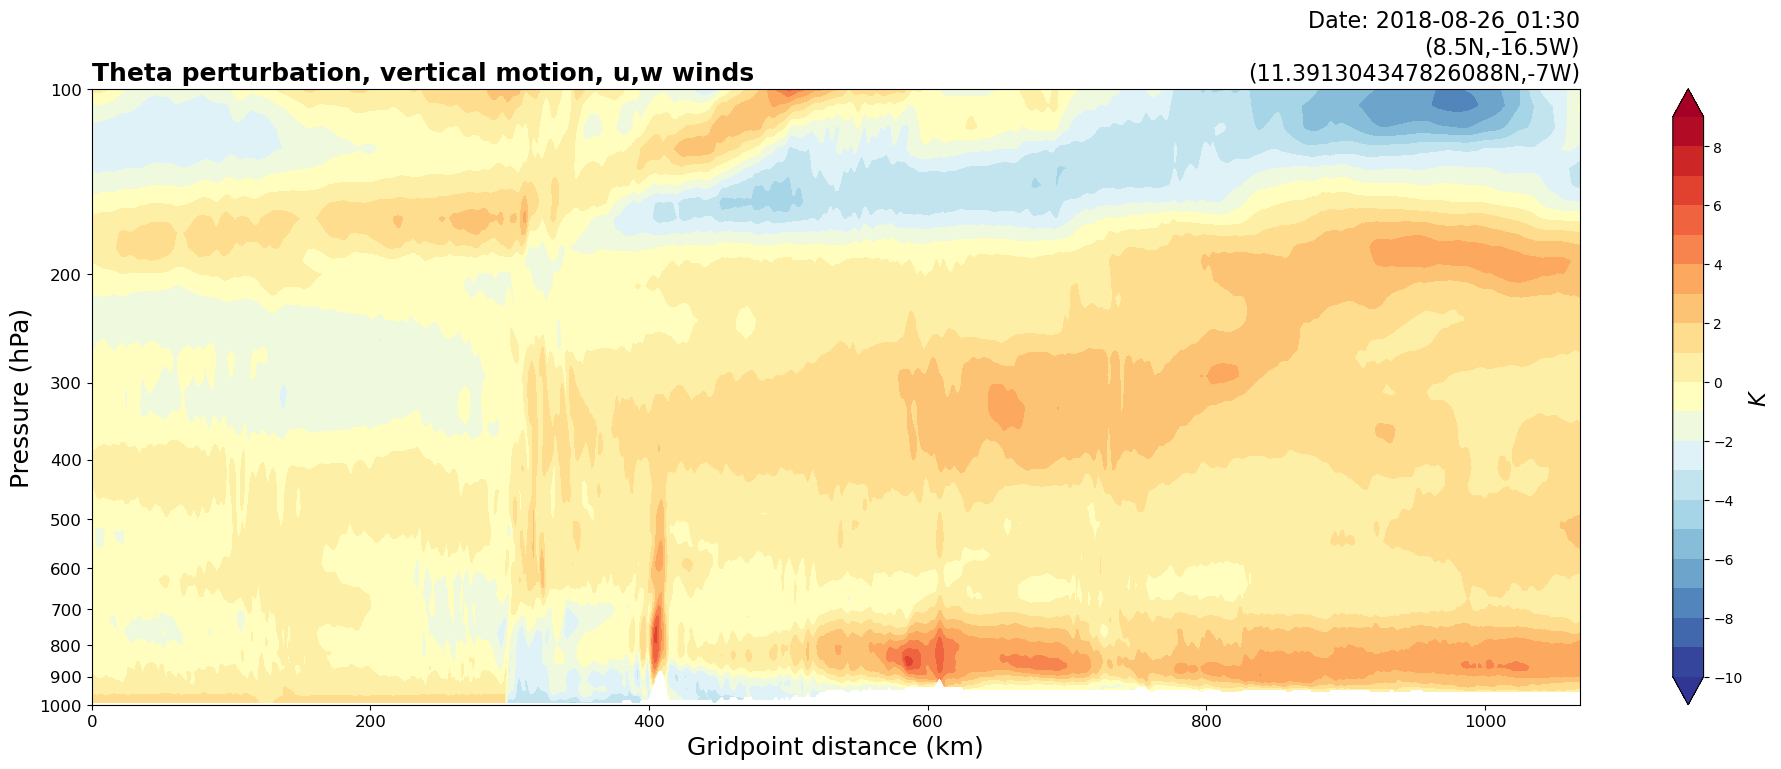

22
319
1.0308222
298
WRF valid time:  2018-08-26_02:00


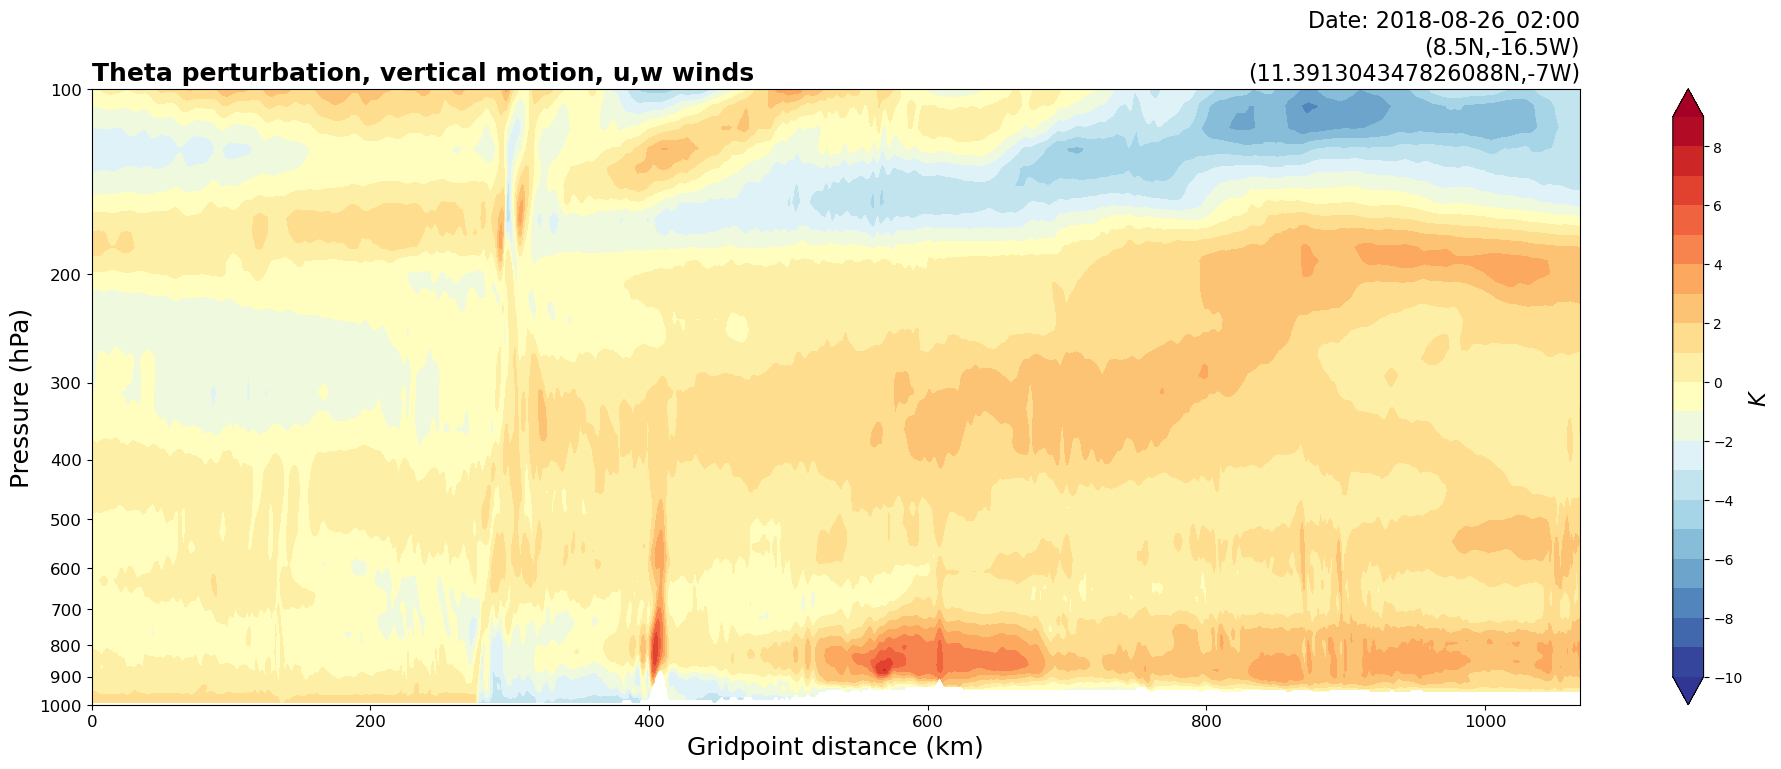

23
298
0.9275296
277
WRF valid time:  2018-08-26_02:30


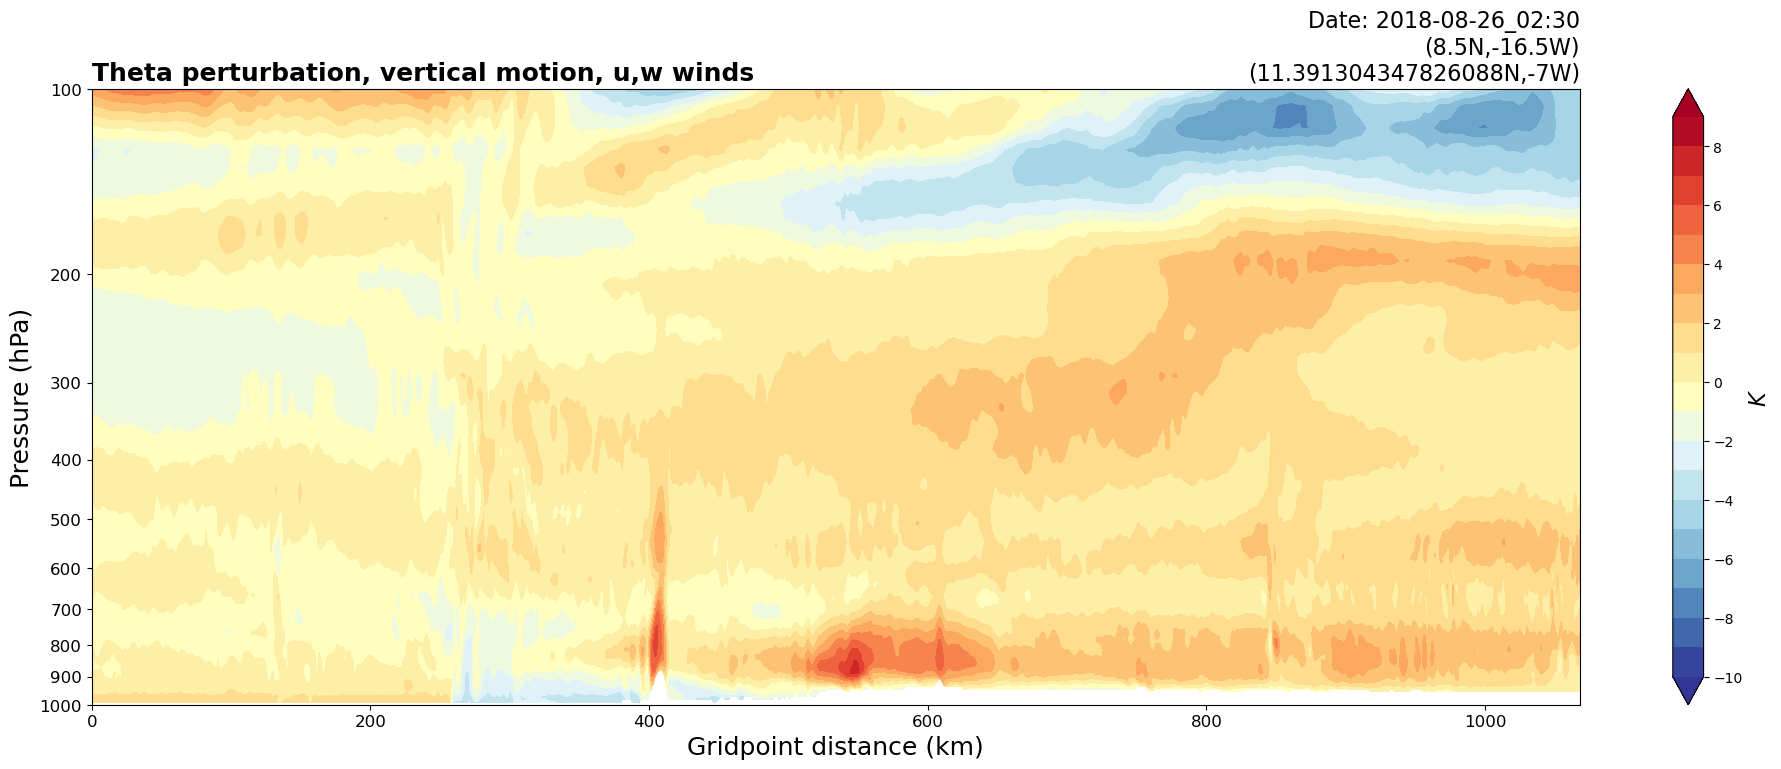

24
277
0.6277995
259
WRF valid time:  2018-08-26_03:00


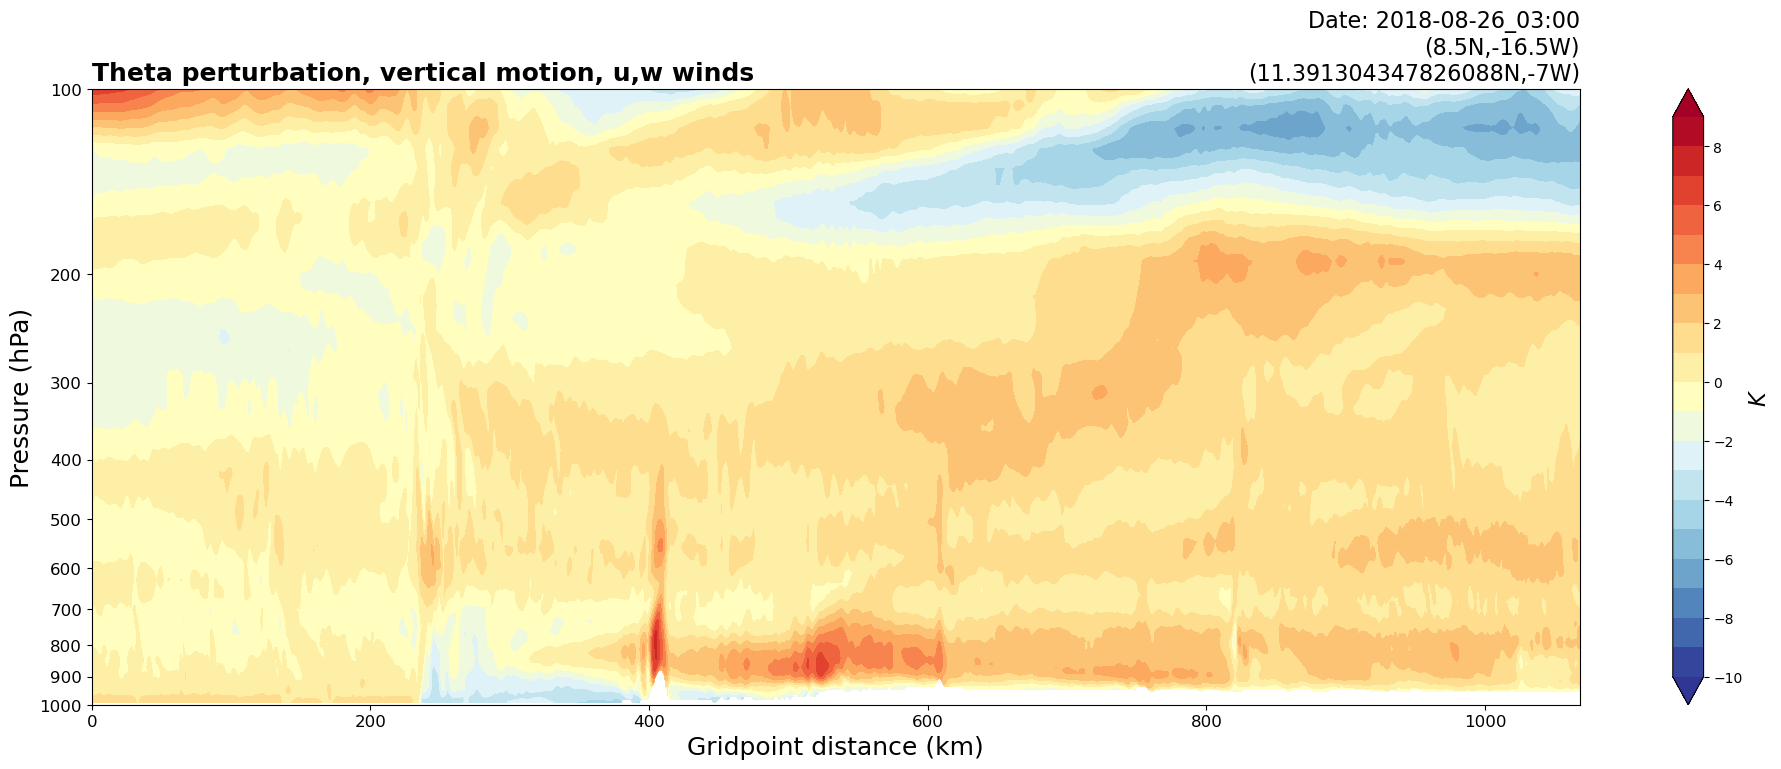

25
259
0.64524454
237
WRF valid time:  2018-08-26_03:30


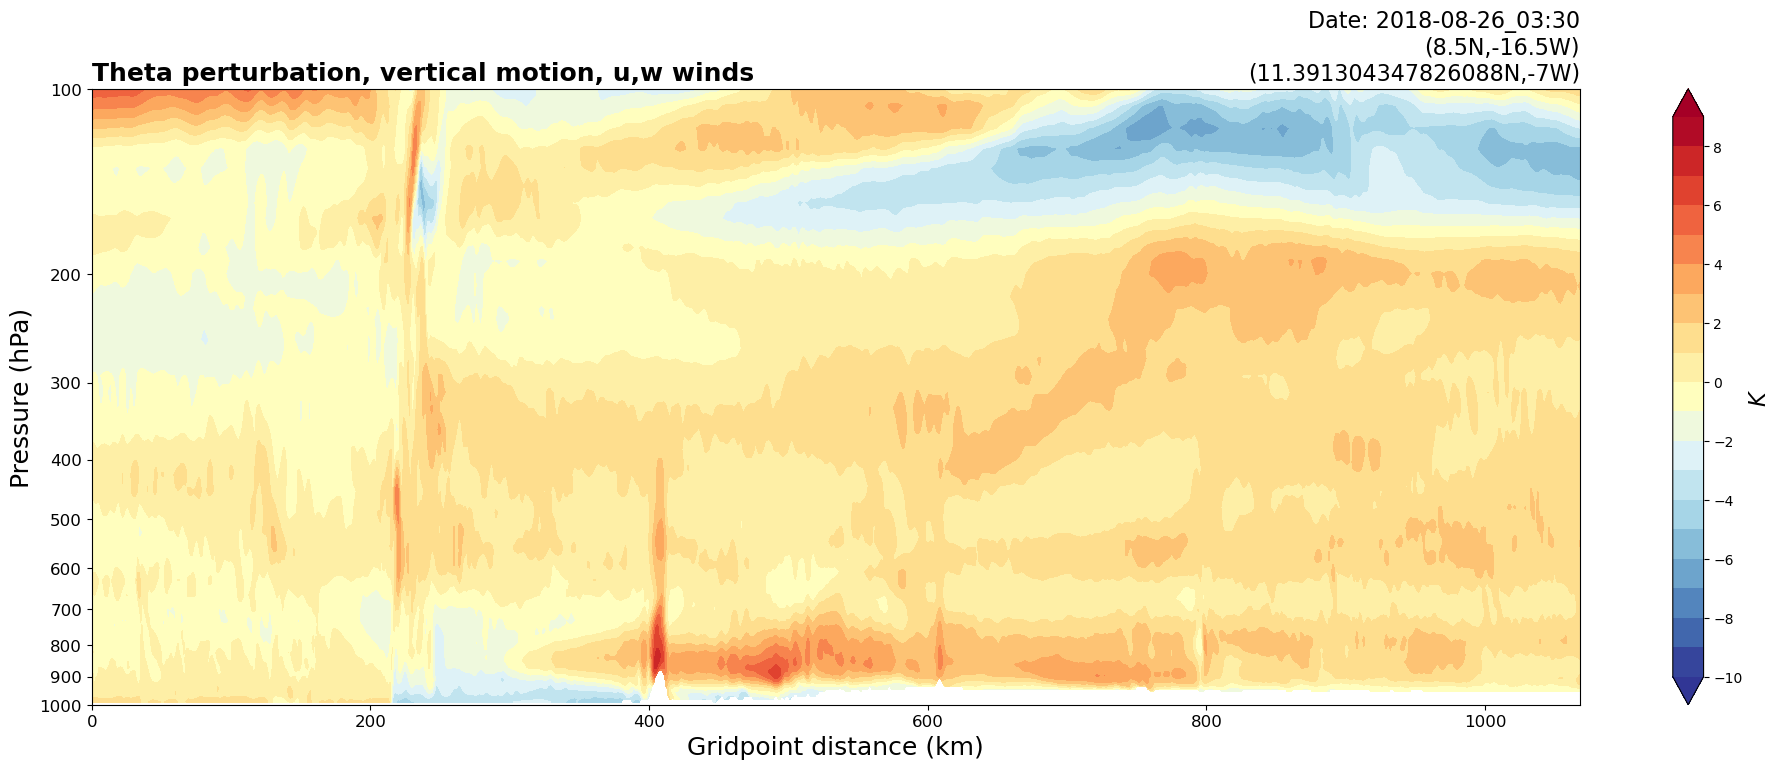

26
237
1.0271196
216
WRF valid time:  2018-08-26_04:00


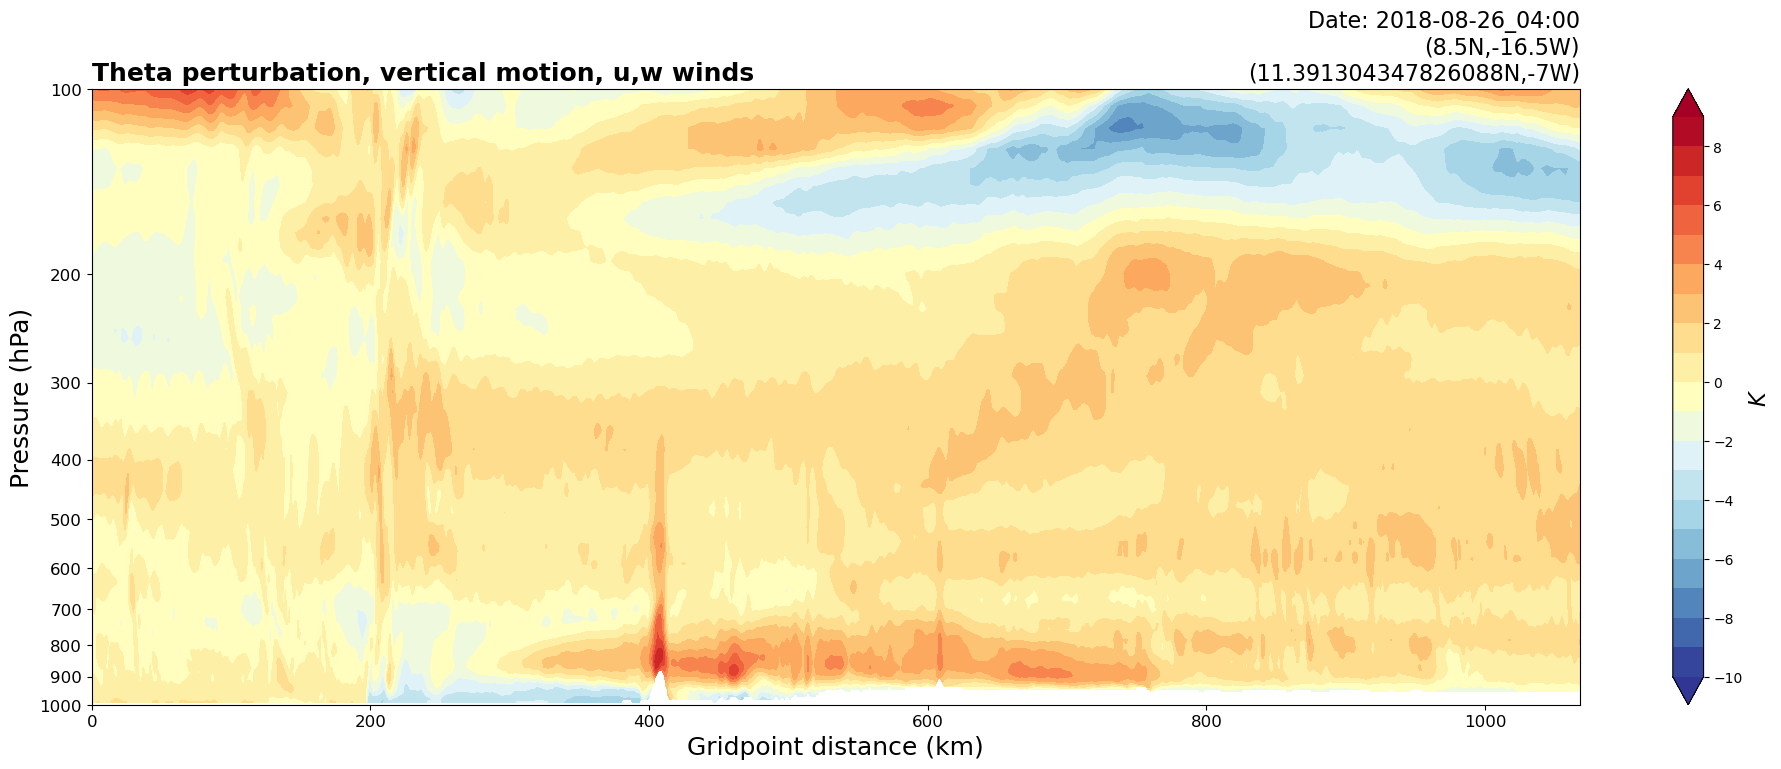

27
216
0.92814744
198
WRF valid time:  2018-08-26_04:30


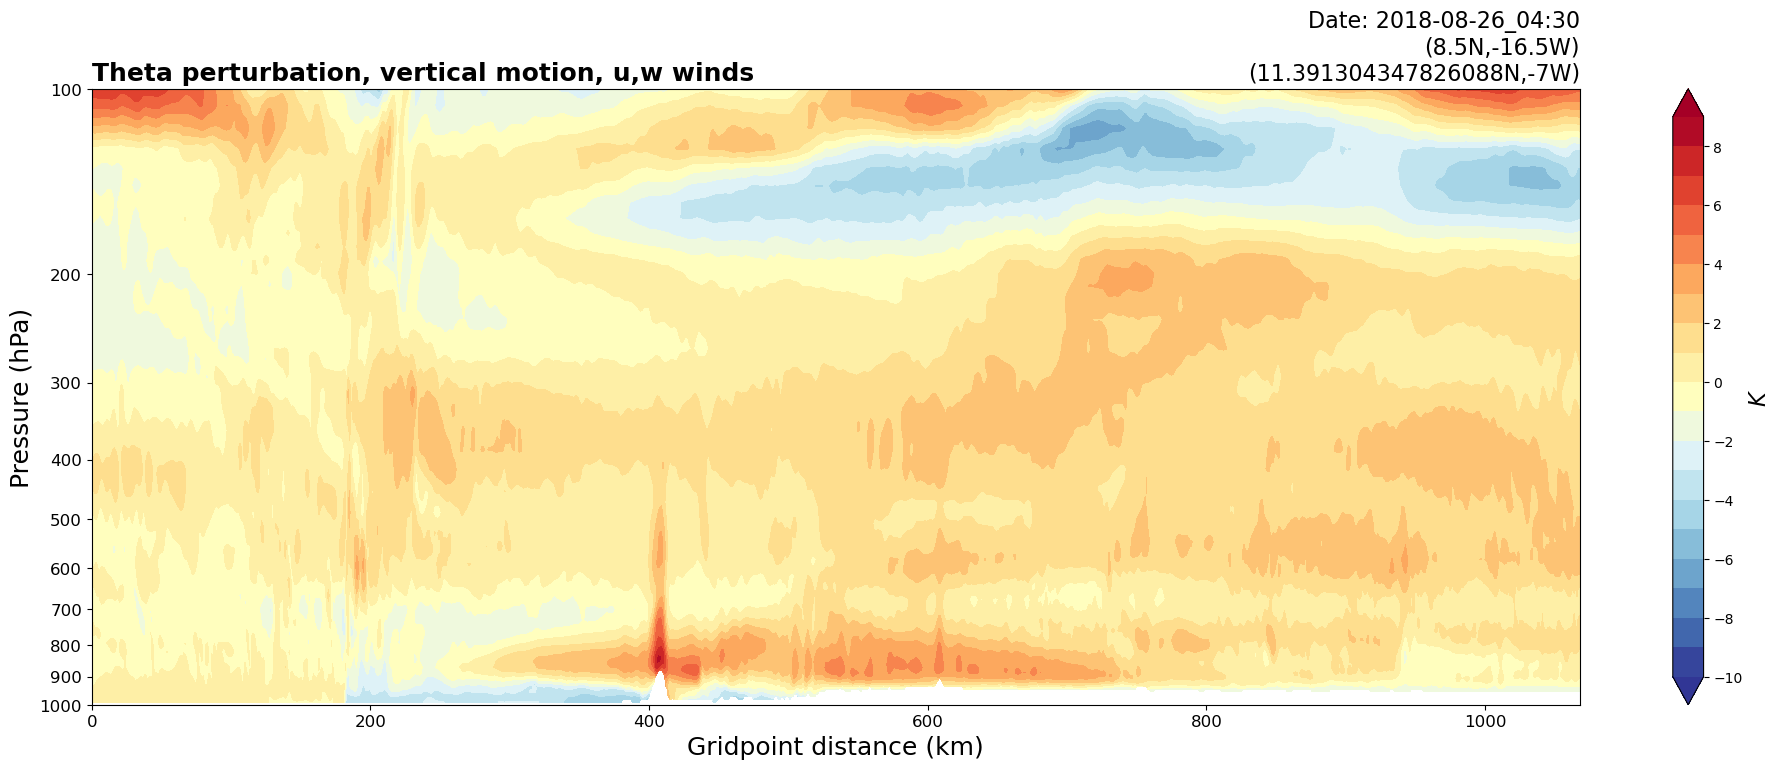

28
198
0.85054624
182
WRF valid time:  2018-08-26_05:00


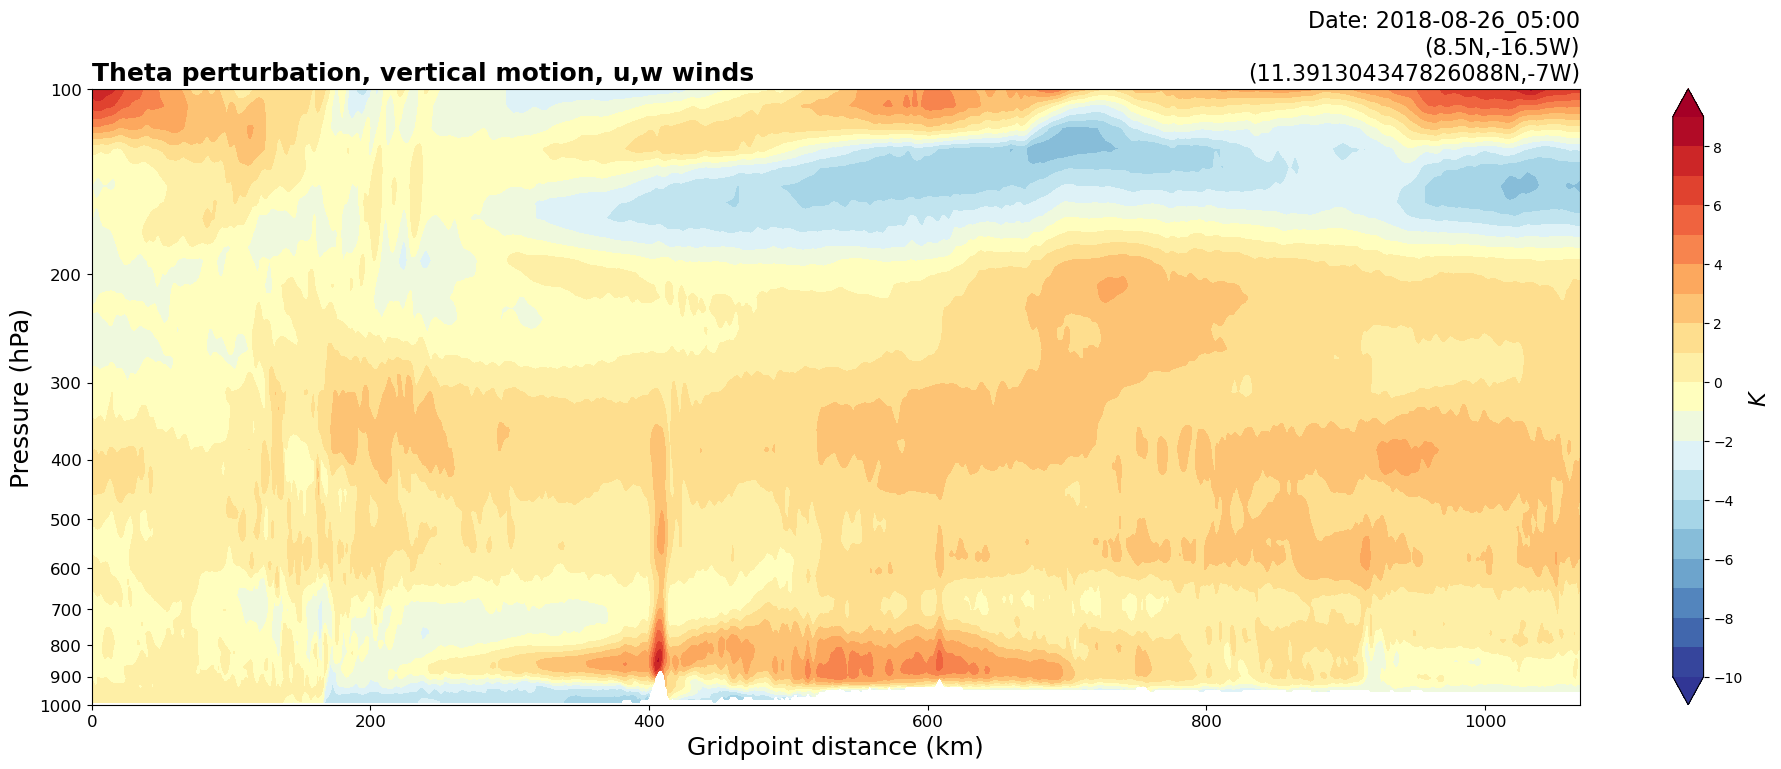

29
182
0.49625182
169
WRF valid time:  2018-08-26_05:30


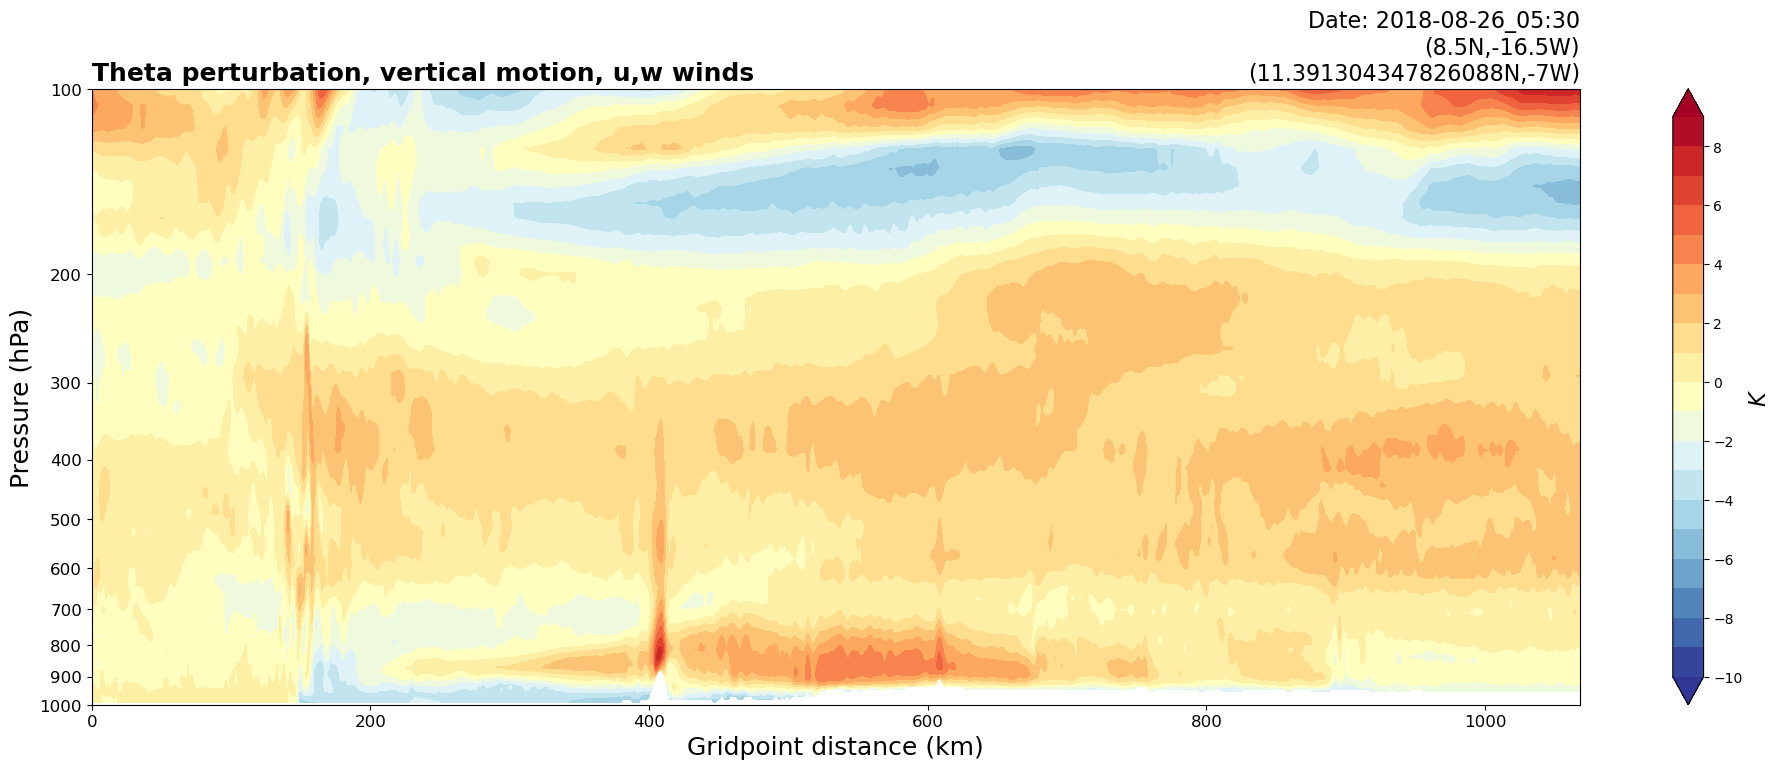

30
169
1.0677202
148
WRF valid time:  2018-08-26_06:00


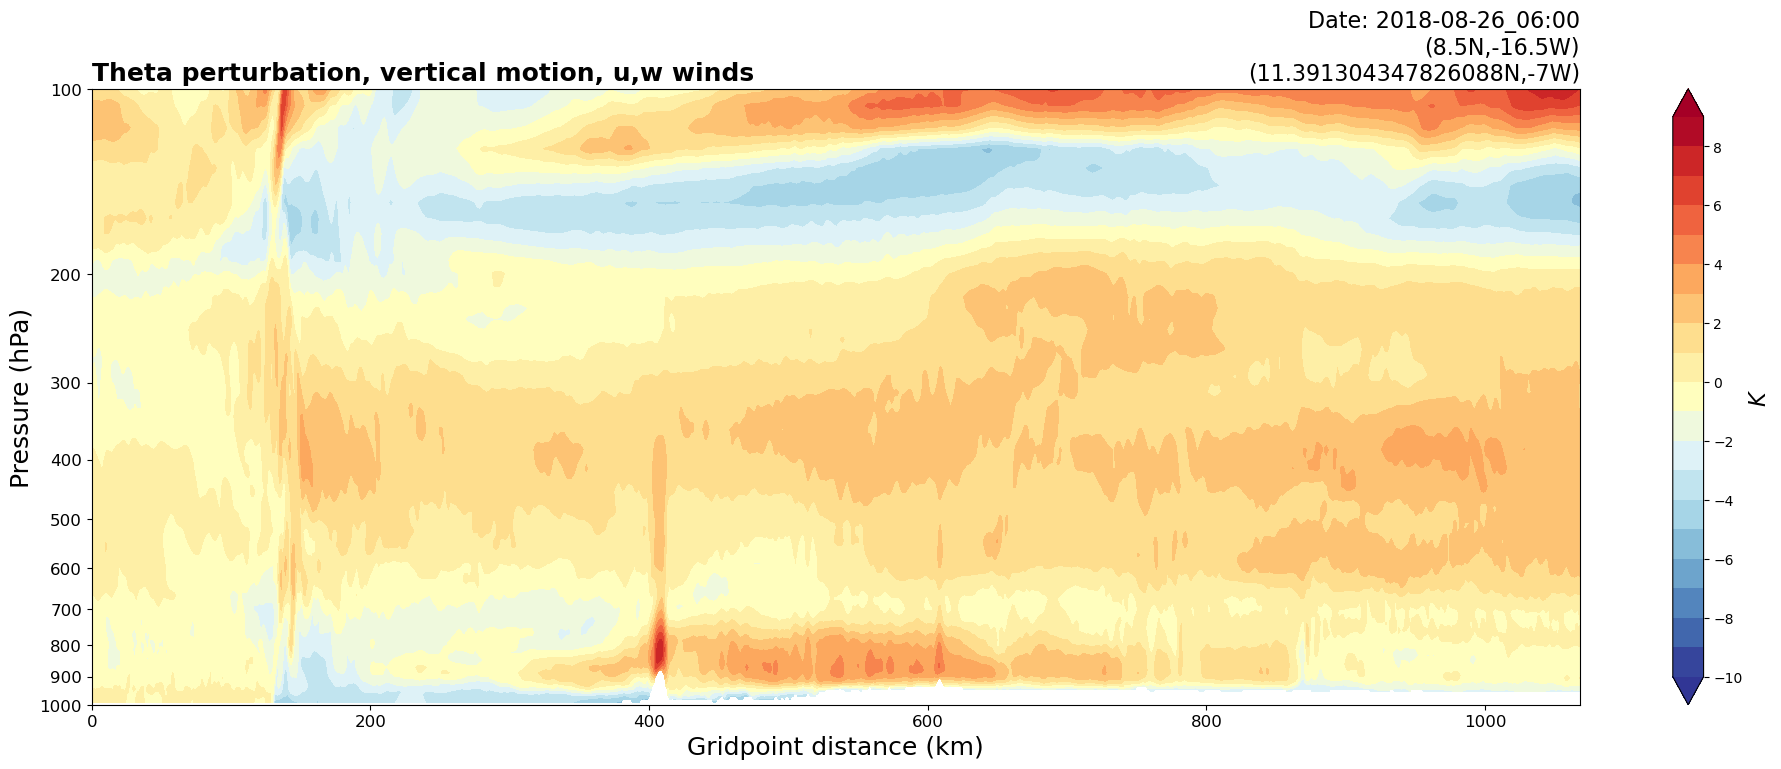

31
148
0.69622886
131
WRF valid time:  2018-08-26_06:30


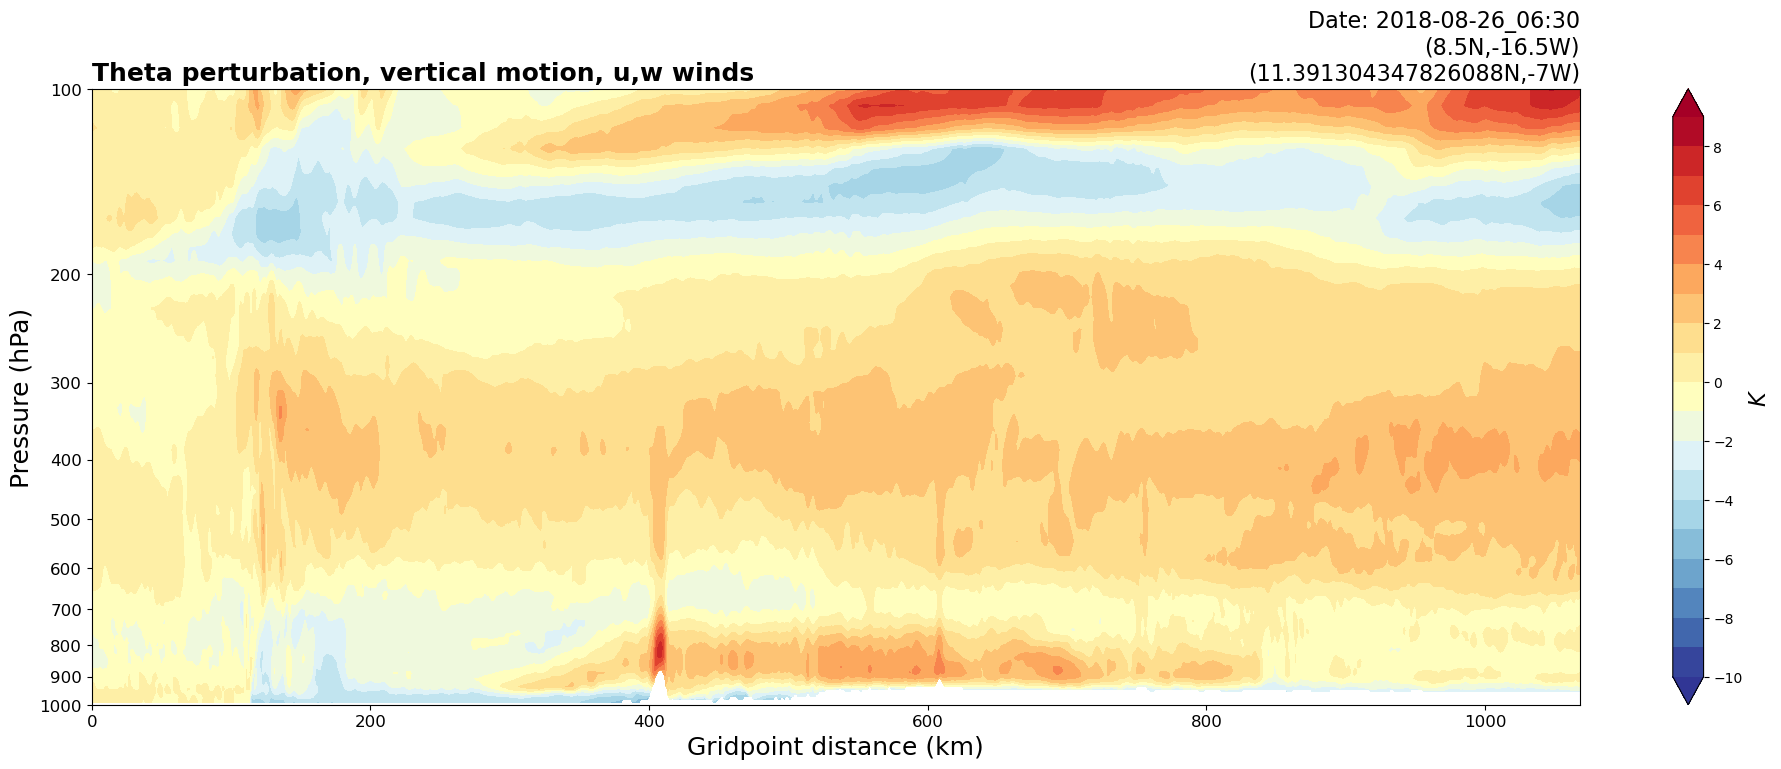

32
131
0.8307178
114
WRF valid time:  2018-08-26_07:00


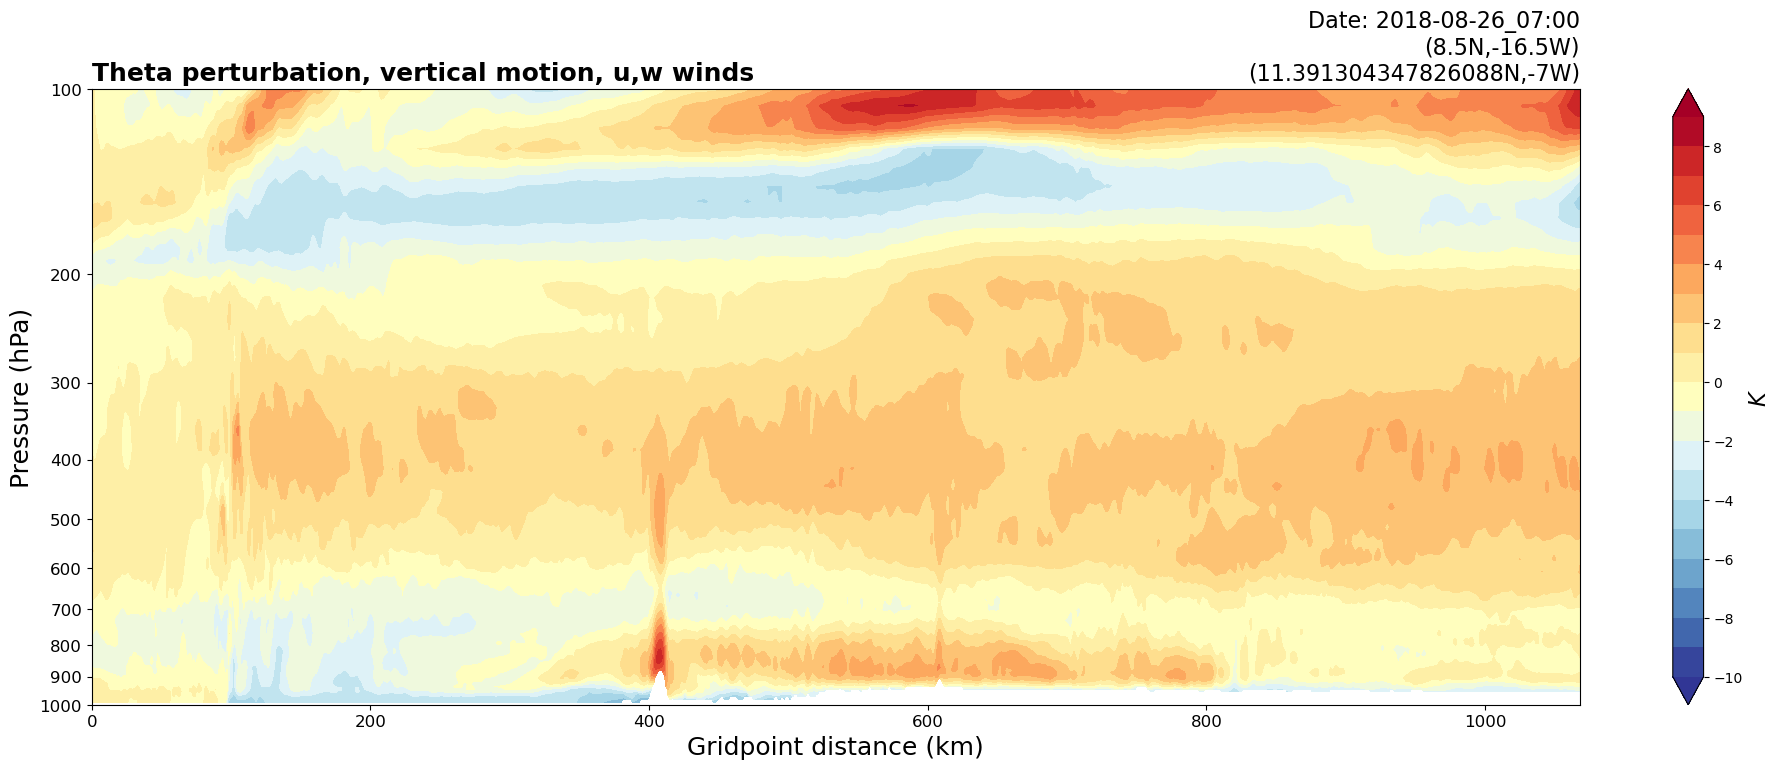

33
114
0.7593773
98
WRF valid time:  2018-08-26_07:30


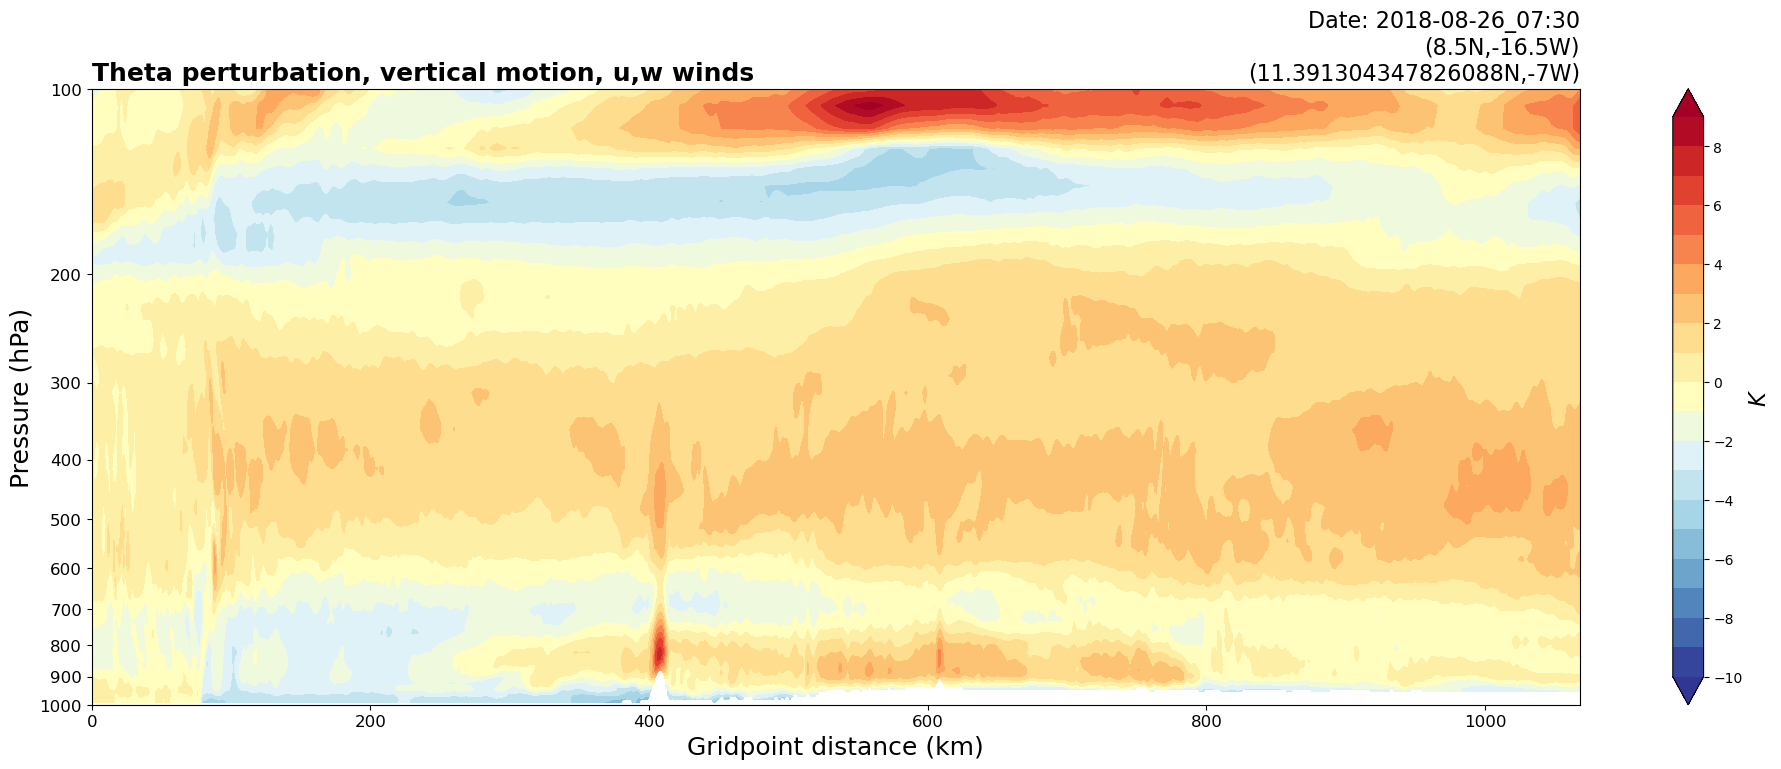

34
98
0.700746
79
WRF valid time:  2018-08-26_08:00


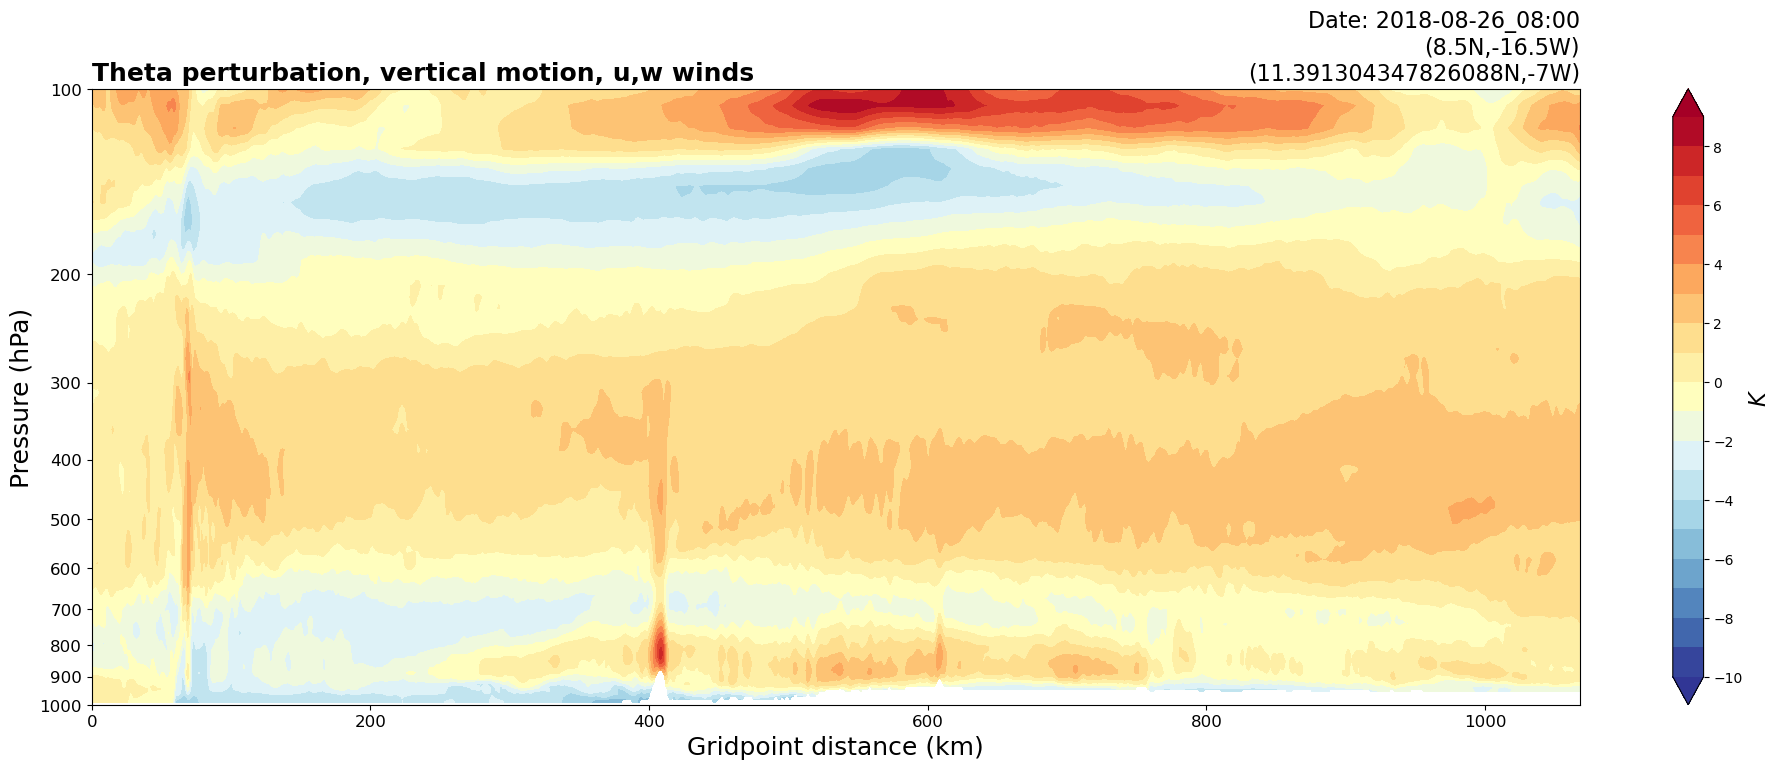

35
79
0.9082856
71
WRF valid time:  2018-08-26_08:30


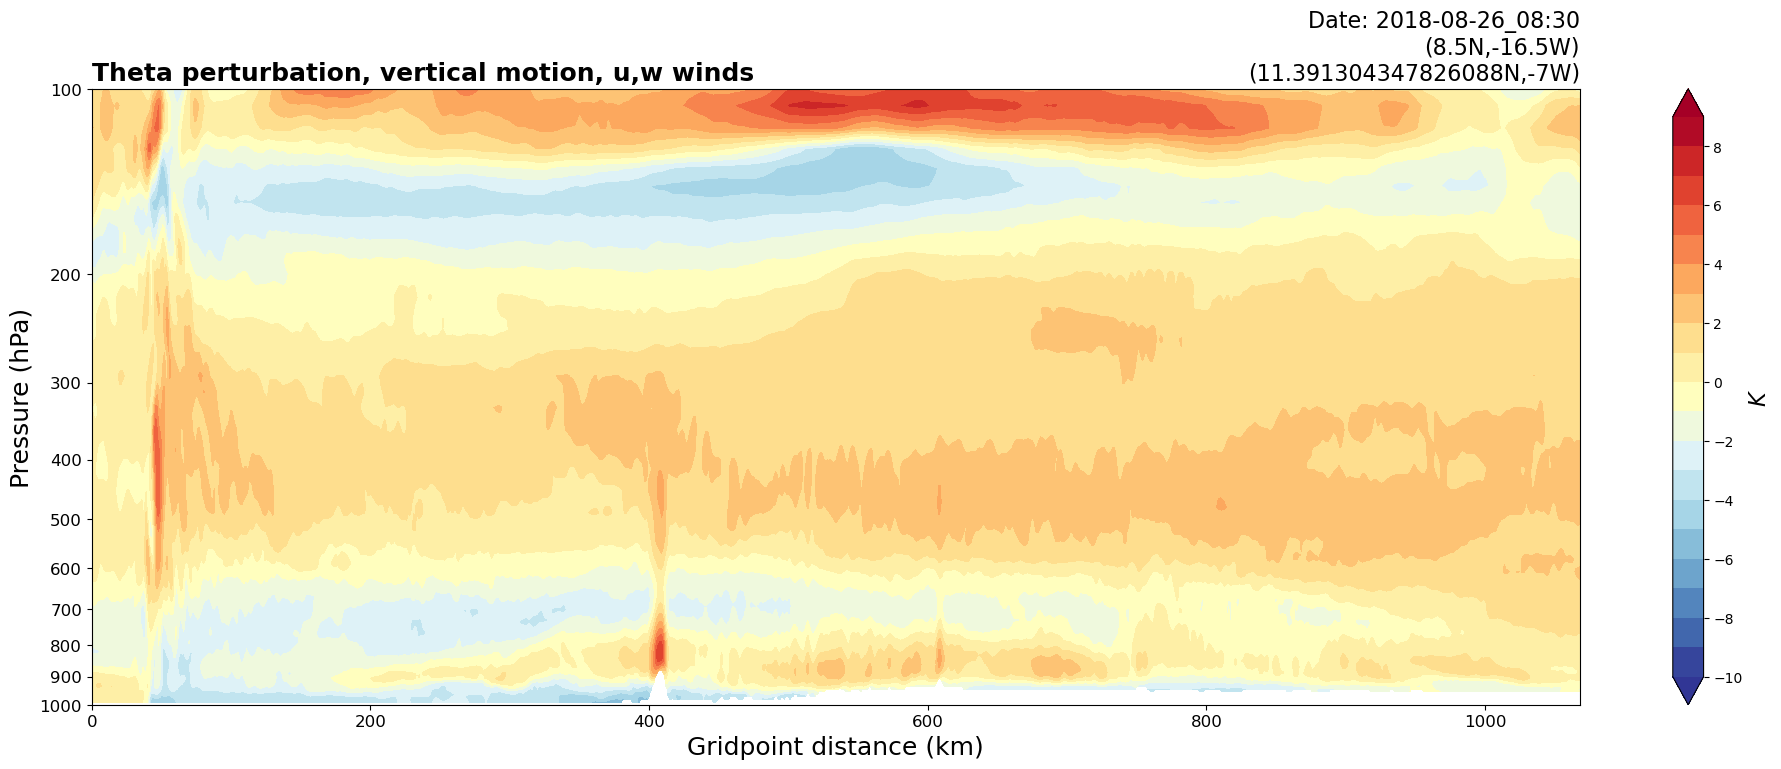

36
71
0.8686231
42
WRF valid time:  2018-08-26_09:00


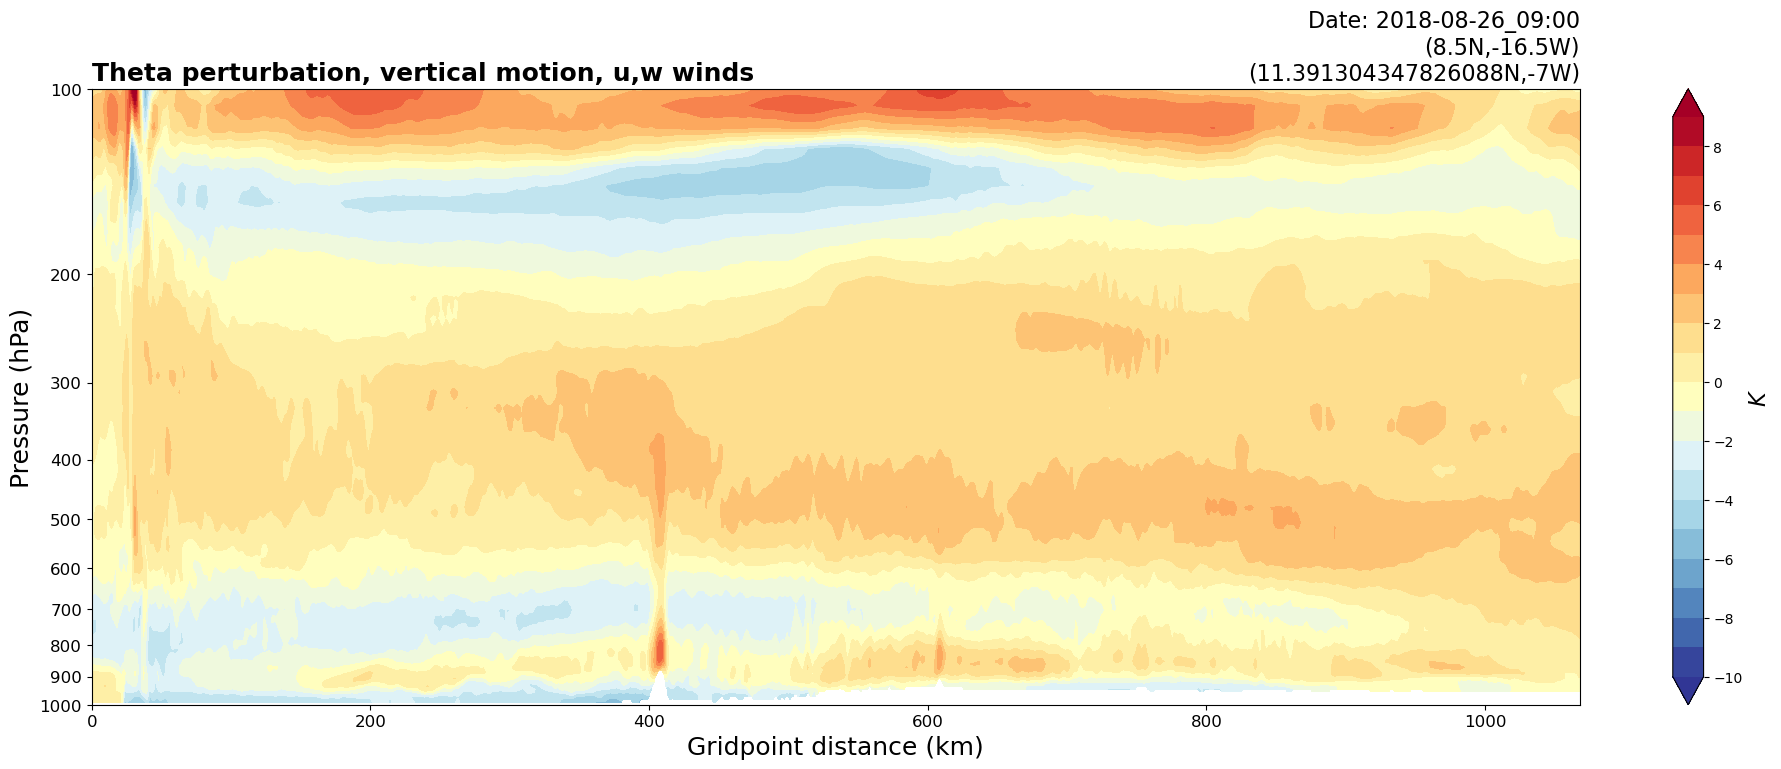

37
42


In [9]:
max_list_idx = []
for i in range(16,57):  # for south
    # Create an aerial abmient theta box ahead of the cross section
    ## for north and south MCSs
    try:
        ## for north and south MCSs
        lat_max2 = lat_max + 0.5  # expand lat cross section box 0.5 degrees south and north
        lat_min2 = lat_min - 0.5
        lon_max2 = lon_max  + (15-i)/4  # for south   
        lon_min2 = lon_max2 - 1.5  
            
        idx = np.where(lat <= lat_min2)
        min_lat_idx_50 = idx[0][-1]
        idx = np.where(lat <= lat_max2)
        max_lat_idx_50 = idx[0][-1]
        
        idx = np.where(lon <= lon_min2)
        min_lon_idx_50 = idx[0][-1]
        idx = np.where(lon <= lon_max2)
        max_lon_idx_50 = idx[0][-1]
        
        wrf_out_data = xr.open_dataset(datafiles[i])
        ncfile = Dataset(datafiles[i])
        Time=wrf.extract_times(ncfile, timeidx=0, method='cat', squeeze=True, cache=None, meta=False, do_xtime=False)
        timestr=(str(Time))
        # Set up one time string for plot titles, another for file names
        titletime=(timestr[0:10]+' '+timestr[11:16])
        filetime=(timestr[0:10]+'_'+timestr[11:16])
        print('WRF valid time: ',filetime)
        
        ua = wrf_out_data["U"]
        va = wrf_out_data["V"]
        wa = wrf_out_data["W"]
        p = wrf_out_data["P"].metpy.quantify()
        pb = wrf_out_data["PB"].metpy.quantify()
        theta_p = wrf_out_data['T'].metpy.quantify()
        
        # Unstagger the winds to match the pressure grid
        ua = destagger(ua, stagger_dim=3)  # Unstagger U in the x-direction
        va = destagger(va, stagger_dim=2)  # Unstagger V in the x-direction
        wa = destagger(wa, stagger_dim=1)  # Unstagger W in the z-direction
        # Grid spacing for vorticity calculation
        dx = ncfile.DX * units("m")
        dy = ncfile.DY * units("m")
        
        u_winds = xr.DataArray(ua)[0]
        v_winds = xr.DataArray(va)[0]
        w_winds = xr.DataArray(wa)[0]
        pres = xr.DataArray(p)[0]
        pb = xr.DataArray(pb)[0]
        theta_p = xr.DataArray(theta_p)[0]
        
        pb = pb.metpy.convert_units('hPa')
        pres = pres.metpy.convert_units('hPa')
        pressure = pres + pb 
        
        # compute aerial average of full theta field 
        theta = theta_p + 300*units('K')            # add 300K to theta model perturbation
        theta_base = theta.sel(south_north=slice(min_lat_idx_50,max_lat_idx_50), 
                                    west_east=slice(min_lon_idx_50,max_lon_idx_50)).mean(dim={'south_north', 'west_east'})
        
        # compute the perturbation from this average, level by level
        theta_pert = theta - theta_base
        theta_pert_slice = theta_pert.sel(bottom_top=slice(0,10))
        pb_slice = pb.sel(bottom_top=slice(0,10))
        
        cross_section  = vertcross(theta_pert, pb, wrfin=ncfile,
                                start_point=start_point,
                                end_point=end_point,
                                latlon=True, meta=True)
        
        
        # Cross section is a 2D array (z vs distance)
        theta_p_cross = cross_section.values
        dist = np.arange(theta_p_cross.shape[1]) # becuase our innermost domain is 1 km, one grid point is approx 1 km
        height = cross_section.coords['vertical']
        f = create_fig()

        ## Getting the edge of the cold pool...
        ds = xr.DataArray(theta_p_cross)
        mean = ds[0:17,:].mean(dim='dim_0') # take the mean of the lowest 17 values of the theta perturbation (elevation)
        grad = np.abs(np.gradient(mean))   # compute the gradient
        if i == 16:    ### For south
            i_max = np.argmax(grad)
            max_list_idx.append(i_max)
        else:
            j = i-17   ### for south     # for all other times, take the previous cold pool edge
            print(j)
            prev_index = max_list_idx[j]
            print(prev_index)
            grad_window = dist[prev_index-70:prev_index-6] # constrain the max theta to within 70 km of the previous point
            max = grad[grad_window].max() # find the max grad value
            print(max)
            i_max = np.argwhere(grad == max)[0][0] # find the index of this value
            print(i_max)
            max_list_idx.append(i_max) # append the index to this list
        # break the loop at the edge of teh domain 
    except ValueError:
        break

In [10]:
## compute ground relative speeds
dist_point = np.array(max_list_idx)
dist_list = []
for i in range(0,len(dist_point)-1):
    dist = dist_point[i+1] - dist_point[i]
    dist_list.append(dist)
dist = np.array(dist_list)
speed = (dist/1800)*1000

In [11]:
## for southern
times_list = pd.date_range('2018-08-25 14:30', '2018-08-26 08:00',freq='0.5h')

In [12]:
len(speed)

37

In [13]:
len(times_list)

36

In [14]:
# Create one dataset with u, v winds at each lat, lon, time coordinate for this ensemble member
ds = xr.Dataset( 
    coords=dict(
        time=("time", times_list),
        speed=("speed", speed),))

In [15]:
# apply regridding and save file
path_out = "/glade/u/home/athornton/wrf_visualization/cold_pool_data/"
file_out = path_out+'south_speed_thesis_shallow.nc'
ds.to_netcdf(path=file_out, format='NETCDF4', mode='w')